# Comparative Analysis: CICIoT2023 vs CICIoMT2024

**Diploma Thesis**: IoT/IoMT Network Intrusion Detection  
**Objective**: Systematic comparison of the two datasets to prepare for integration  
**References**: Neto et al. (2023) CICIoT2023, Dadkhah et al. (2024) CICIoMT2024  

---

## Table of Contents

1. [Overview & Methodology Comparison](#1-overview--methodology-comparison)
2. [Imports & Configuration](#2-imports--configuration)
3. [Data Loading Strategy](#3-data-loading-strategy)
4. [Feature Schema Comparison](#4-feature-schema-comparison)
5. [Feature Alignment & Mapping](#5-feature-alignment--mapping)
6. [Label Comparison & Attack Taxonomy](#6-label-comparison--attack-taxonomy)
7. [Label Harmonization Proposal](#7-label-harmonization-proposal)
8. [Statistical Comparison of Common Features](#8-statistical-comparison-of-common-features)
9. [Scale & Class Imbalance Comparison](#9-scale--class-imbalance-comparison)
10. [Correlation Structure Comparison](#10-correlation-structure-comparison)
11. [Summary & Integration Considerations](#11-summary--integration-considerations)

## 1. Overview & Methodology Comparison

### Methodology Comparison

| Characteristic | CICIoT2023 | CICIoMT2024 |
|---|---|---|
| **Application domain** | General IoT | IoMT (Internet of Medical Things) |
| **Institution** | CIC, University of New Brunswick | CIC, University of New Brunswick |
| **Devices** | 105 (real IoT devices) | 40 (25 real + 15 simulated IoMT) |
| **Attack types** | 33 attack types | 18 attack types |
| **Protocols** | WiFi, Ethernet | WiFi, MQTT, BLE |
| **Feature extraction** | DPKT (window-based aggregation) | DPKT (window-based aggregation) |
| **Window sizes** | 10 / 100 packets | 10 / 100 packets |
| **Capture tool** | TCPDUMP | TCPDUMP |
| **Format** | PCAP → CSV | PCAP → CSV |
| **Attackers** | Raspberry Pi's | 4 Raspberry Pi's + iPad |
| **Label scheme (CSV)** | Column `Label` | Filename-based |
| **Duration column** | `Time_To_Live` (actual TTL) | `Duration` (actually TTL) |

### Common Ground

Both datasets:
- Were created by the **same research laboratory** (CIC, UNB)
- Use the **same feature extraction pipeline** (TCPDUMP + DPKT)
- Apply **window-based aggregation** (10 or 100 packets per row)
- Include **overlapping attack categories** (DDoS, DoS, Recon, Spoofing)

### Key Differences

- **Domain**: CICIoT2023 = generic IoT, CICIoMT2024 = healthcare/medical IoT
- **Scale**: CICIoT2023 (44.7M rows, 63 files) >> CICIoMT2024 (8.3M rows, 72 files)
- **MQTT attacks**: Only in CICIoMT2024 (5 types)
- **Web/Brute Force/Mirai attacks**: Only in CICIoT2023
- **Extra features**: CICIoMT2024 has 6 additional features (Srate, Drate, Magnitue, Radius, Covariance, Weight)

## 2. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import re
import glob
from pathlib import Path
from collections import OrderedDict
import warnings

warnings.filterwarnings('ignore')

# ── Paths ──
CICIOT2023_DIR = Path('../data/raw/CICIoT2023')
CICIOMT2024_DIR = Path('../data/raw/CICIoMT2024')
CICIOMT2024_TRAIN = CICIOMT2024_DIR / 'train'
CICIOMT2024_TEST = CICIOMT2024_DIR / 'test'

# ── Plot style ──
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.facecolor': 'white',
})

# ── Color palettes ──
DATASET_COLORS = {
    'CICIoT2023': '#e74c3c',
    'CICIoMT2024': '#3498db',
}

CATEGORY_COLORS = {
    'Benign': '#2ecc71',
    'DDoS': '#e74c3c',
    'DoS': '#e67e22',
    'Reconnaissance': '#3498db',
    'Spoofing': '#9b59b6',
    'MQTT': '#1abc9c',
    'Mirai': '#f39c12',
    'Web-based': '#e84393',
    'Brute Force': '#6c5ce7',
    'DNS': '#00cec9',
    'Backdoor': '#636e72',
}

# ── Verify paths ──
print('Configuration loaded successfully.')
print(f'CICIoT2023 directory:  {CICIOT2023_DIR} (exists: {CICIOT2023_DIR.exists()})')
print(f'CICIoMT2024 directory: {CICIOMT2024_DIR} (exists: {CICIOMT2024_DIR.exists()})')
print(f'  Train: {CICIOMT2024_TRAIN} (exists: {CICIOMT2024_TRAIN.exists()})')
print(f'  Test:  {CICIOMT2024_TEST} (exists: {CICIOMT2024_TEST.exists()})')

iot2023_files = sorted(CICIOT2023_DIR.glob('Merged*.csv'))
iomt2024_train_files = sorted(CICIOMT2024_TRAIN.glob('*.csv'))
iomt2024_test_files = sorted(CICIOMT2024_TEST.glob('*.csv'))
print(f'\nCICIoT2023 CSV files:  {len(iot2023_files)}')
print(f'CICIoMT2024 CSV files: {len(iomt2024_train_files)} train + {len(iomt2024_test_files)} test = {len(iomt2024_train_files) + len(iomt2024_test_files)}')

Configuration loaded successfully.
CICIoT2023 directory:  ../data/raw/CICIoT2023 (exists: True)
CICIoMT2024 directory: ../data/raw/CICIoMT2024 (exists: True)
  Train: ../data/raw/CICIoMT2024/train (exists: True)
  Test:  ../data/raw/CICIoMT2024/test (exists: True)

CICIoT2023 CSV files:  63
CICIoMT2024 CSV files: 51 train + 21 test = 72


## 3. Data Loading Strategy

### Loading Strategy

Due to size (CICIoT2023: ~44.7M rows), we use **strategic sampling**:

1. **Headers**: Load only column names (feature comparison)
2. **Labels**: Load only the `Label` column in CICIoT2023 (label comparison)
3. **Sample**: Random sample ~500K rows per dataset (statistical comparison)

This allows full analysis without excessive memory usage.

In [2]:
# ══════════════════════════════════════════════════════════════════════
# 3a. Load column schemas (headers only)
# ══════════════════════════════════════════════════════════════════════

# CICIoT2023 columns
iot2023_cols_df = pd.read_csv(iot2023_files[0], nrows=0)
iot2023_all_cols = list(iot2023_cols_df.columns)

# CICIoMT2024 columns
iomt2024_cols_df = pd.read_csv(iomt2024_train_files[0], nrows=0)
iomt2024_all_cols = list(iomt2024_cols_df.columns)

print(f'CICIoT2023 columns:  {len(iot2023_all_cols)}')
print(f'CICIoMT2024 columns: {len(iomt2024_all_cols)}')

CICIoT2023 columns:  40
CICIoMT2024 columns: 45


In [3]:
%%time
# ══════════════════════════════════════════════════════════════════════
# 3b. Load CICIoT2023 labels (Label column only -- all files)
# ══════════════════════════════════════════════════════════════════════

print('Loading CICIoT2023 labels (Label column only)...')
iot2023_labels_list = []
iot2023_file_rows = {}

for f in iot2023_files:
    lbl = pd.read_csv(f, usecols=['Label'])
    iot2023_file_rows[f.name] = len(lbl)
    iot2023_labels_list.append(lbl)

iot2023_labels = pd.concat(iot2023_labels_list, ignore_index=True)
iot2023_total_rows = len(iot2023_labels)
print(f'Total CICIoT2023 rows: {iot2023_total_rows:,}')
print(f'Unique labels: {iot2023_labels["Label"].nunique()}')

Loading CICIoT2023 labels (Label column only)...


Total CICIoT2023 rows: 44,763,144


Unique labels: 34
CPU times: user 22.6 s, sys: 1.44 s, total: 24 s
Wall time: 25.1 s


In [4]:
%%time
# ══════════════════════════════════════════════════════════════════════
# 3c. Load CICIoMT2024 labels (derived from filenames -- all files)
# ══════════════════════════════════════════════════════════════════════

def extract_iomt_label(filename: str) -> str:
    """Extract attack label from CICIoMT2024 filename.
    
    Examples:
        Benign_train.pcap.csv              -> Benign
        TCP_IP-DDoS-ICMP3_train.pcap.csv   -> TCP_IP-DDoS-ICMP
        MQTT-DoS-Connect_Flood_train.pcap.csv -> MQTT-DoS-Connect_Flood
    """
    name = re.sub(r'_(train|test)\.pcap\.csv$', '', filename)
    name = re.sub(r'\d+$', '', name)
    return name


print('Loading CICIoMT2024 labels (from filenames)...')
iomt2024_labels_list = []
iomt2024_file_rows = {}

for split_dir, split_name in [(CICIOMT2024_TRAIN, 'train'), (CICIOMT2024_TEST, 'test')]:
    for f in sorted(split_dir.glob('*.csv')):
        if f.name == '.gitkeep':
            continue
        label = extract_iomt_label(f.name)
        nrows = sum(1 for _ in open(f)) - 1  # count lines, exclude header
        iomt2024_file_rows[f.name] = nrows
        iomt2024_labels_list.append(pd.DataFrame({'label': [label] * nrows}))

iomt2024_labels = pd.concat(iomt2024_labels_list, ignore_index=True)
iomt2024_total_rows = len(iomt2024_labels)
print(f'Total CICIoMT2024 rows: {iomt2024_total_rows:,}')
print(f'Unique labels: {iomt2024_labels["label"].nunique()}')

Loading CICIoMT2024 labels (from filenames)...


Total CICIoMT2024 rows: 8,322,896
Unique labels: 19
CPU times: user 1.2 s, sys: 506 ms, total: 1.7 s
Wall time: 2.64 s


In [5]:
%%time
# ══════════════════════════════════════════════════════════════════════
# 3d. Load feature SAMPLES for statistical comparison
# ══════════════════════════════════════════════════════════════════════
# Strategy: load ~500K rows from each dataset via uniform file sampling

SAMPLE_TARGET = 500_000

# ── CICIoT2023 sample ──
print(f'Sampling ~{SAMPLE_TARGET:,} rows from CICIoT2023...')
iot2023_feature_cols = [c for c in iot2023_all_cols if c != 'Label']
rows_per_file = max(1, SAMPLE_TARGET // len(iot2023_files))

sample_dfs_2023 = []
for f in iot2023_files:
    df_tmp = pd.read_csv(f)
    if len(df_tmp) > rows_per_file:
        df_tmp = df_tmp.sample(n=rows_per_file, random_state=42)
    sample_dfs_2023.append(df_tmp)

df_sample_2023 = pd.concat(sample_dfs_2023, ignore_index=True)
print(f'CICIoT2023 sample: {len(df_sample_2023):,} rows')

# ── CICIoMT2024 sample ──
print(f'\nSampling ~{SAMPLE_TARGET:,} rows from CICIoMT2024...')
all_iomt_files = sorted(CICIOMT2024_TRAIN.glob('*.csv')) + sorted(CICIOMT2024_TEST.glob('*.csv'))
all_iomt_files = [f for f in all_iomt_files if f.name != '.gitkeep']
rows_per_file_iomt = max(1, SAMPLE_TARGET // len(all_iomt_files))

sample_dfs_2024 = []
for f in all_iomt_files:
    df_tmp = pd.read_csv(f)
    df_tmp['label'] = extract_iomt_label(f.name)
    if len(df_tmp) > rows_per_file_iomt:
        df_tmp = df_tmp.sample(n=rows_per_file_iomt, random_state=42)
    sample_dfs_2024.append(df_tmp)

df_sample_2024 = pd.concat(sample_dfs_2024, ignore_index=True)
print(f'CICIoMT2024 sample: {len(df_sample_2024):,} rows')

Sampling ~500,000 rows from CICIoT2023...


CICIoT2023 sample: 499,968 rows

Sampling ~500,000 rows from CICIoMT2024...


CICIoMT2024 sample: 449,316 rows
CPU times: user 52.7 s, sys: 2.56 s, total: 55.3 s
Wall time: 55.5 s


## 4. Feature Schema Comparison

Comparison of feature schemas between the two datasets: which features are common, which are unique.

In [6]:
# ══════════════════════════════════════════════════════════════════════
# 4a. Column-level comparison
# ══════════════════════════════════════════════════════════════════════

cols_2023 = set(iot2023_all_cols)
cols_2024 = set(iomt2024_all_cols)

common_cols = sorted(cols_2023 & cols_2024)
only_2023 = sorted(cols_2023 - cols_2024)
only_2024 = sorted(cols_2024 - cols_2023)

print('Feature Schema Comparison')
print('=' * 70)
print(f'CICIoT2023 total columns:  {len(cols_2023)}')
print(f'CICIoMT2024 total columns: {len(cols_2024)}')
print(f'\nCommon columns (by name):   {len(common_cols)}')
print(f'Only in CICIoT2023:        {len(only_2023)}')
print(f'Only in CICIoMT2024:       {len(only_2024)}')

print(f'\n{"─" * 70}')
print(f'{"Common Features":30s} | {"Only CICIoT2023":20s} | {"Only CICIoMT2024":20s}')
print(f'{"─" * 70}')

max_rows = max(len(common_cols), len(only_2023), len(only_2024))
for i in range(max_rows):
    c1 = common_cols[i] if i < len(common_cols) else ''
    c2 = only_2023[i] if i < len(only_2023) else ''
    c3 = only_2024[i] if i < len(only_2024) else ''
    print(f'{c1:30s} | {c2:20s} | {c3:20s}')

Feature Schema Comparison
CICIoT2023 total columns:  40
CICIoMT2024 total columns: 45

Common columns (by name):   38
Only in CICIoT2023:        2
Only in CICIoMT2024:       7

──────────────────────────────────────────────────────────────────────
Common Features                | Only CICIoT2023      | Only CICIoMT2024    
──────────────────────────────────────────────────────────────────────
ARP                            | Label                | Covariance          
AVG                            | Time_To_Live         | Drate               
DHCP                           |                      | Duration            
DNS                            |                      | Magnitue            
HTTP                           |                      | Radius              
HTTPS                          |                      | Srate               
Header_Length                  |                      | Weight              
IAT                            |                      |          

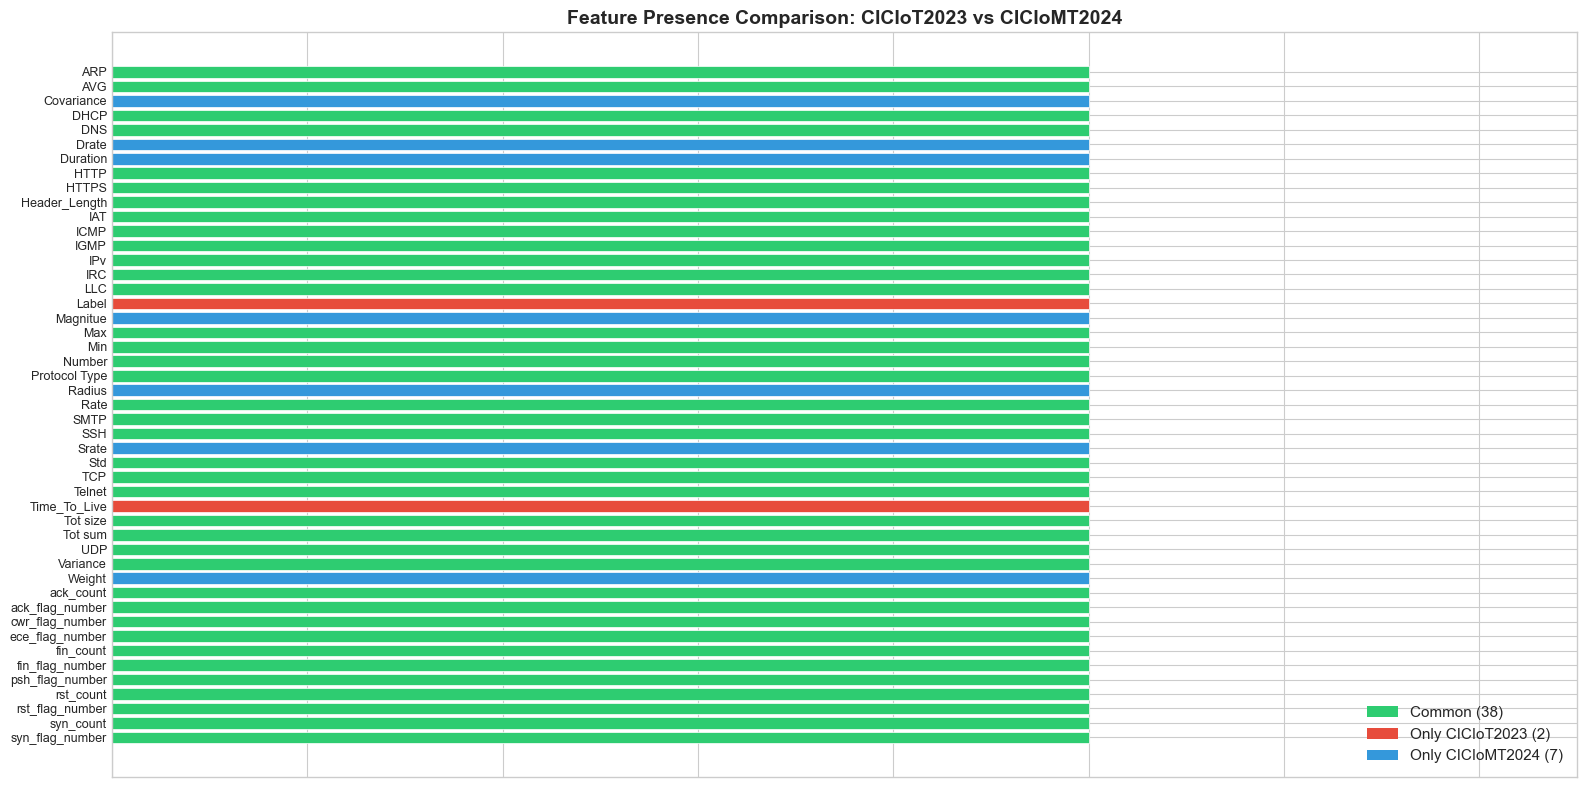

In [7]:
# ══════════════════════════════════════════════════════════════════════
# 4b. Visual Venn-style comparison
# ══════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(16, 8))

# Build comparison data
all_features = sorted(cols_2023 | cols_2024)
comparison_data = []
for feat in all_features:
    in_2023 = feat in cols_2023
    in_2024 = feat in cols_2024
    if in_2023 and in_2024:
        status = 'Common'
    elif in_2023:
        status = 'Only CICIoT2023'
    else:
        status = 'Only CICIoMT2024'
    comparison_data.append({'Feature': feat, 'Status': status})

df_comp = pd.DataFrame(comparison_data)

# Color mapping
status_colors = {
    'Common': '#2ecc71',
    'Only CICIoT2023': '#e74c3c',
    'Only CICIoMT2024': '#3498db',
}

# Horizontal bar chart
y_pos = range(len(df_comp))
colors = [status_colors[s] for s in df_comp['Status']]
bars = ax.barh(y_pos, [1] * len(df_comp), color=colors, edgecolor='white', linewidth=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_comp['Feature'], fontsize=9)
ax.set_xlim(0, 1.5)
ax.set_xlabel('')
ax.set_title('Feature Presence Comparison: CICIoT2023 vs CICIoMT2024', fontsize=14, fontweight='bold')
ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ecc71', label=f'Common ({len(common_cols)})'),
    Patch(facecolor='#e74c3c', label=f'Only CICIoT2023 ({len(only_2023)})'),
    Patch(facecolor='#3498db', label=f'Only CICIoMT2024 ({len(only_2024)})'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [8]:
# ══════════════════════════════════════════════════════════════════════
# 4c. Data type comparison for common features
# ══════════════════════════════════════════════════════════════════════

# Feature columns only (exclude metadata like Label)
iot2023_feature_cols = [c for c in iot2023_all_cols if c != 'Label']
iomt2024_feature_cols = iomt2024_all_cols  # No Label column in CSV

print('Data Type Comparison (common features)')
print('=' * 70)
print(f'{"Feature":30s} | {"CICIoT2023":15s} | {"CICIoMT2024":15s} | Match')
print(f'{"─" * 70}')

# Use samples to check dtypes
match_count = 0
common_feature_cols = [c for c in common_cols if c != 'Label']

for col in common_feature_cols:
    dtype_2023 = str(df_sample_2023[col].dtype) if col in df_sample_2023.columns else 'N/A'
    dtype_2024 = str(df_sample_2024[col].dtype) if col in df_sample_2024.columns else 'N/A'
    match = '  ✓' if dtype_2023 == dtype_2024 else '  ✗'
    if dtype_2023 == dtype_2024:
        match_count += 1
    print(f'{col:30s} | {dtype_2023:15s} | {dtype_2024:15s} | {match}')

print(f'\nType match rate: {match_count}/{len(common_feature_cols)} ({match_count/len(common_feature_cols)*100:.1f}%)')

Data Type Comparison (common features)
Feature                        | CICIoT2023      | CICIoMT2024     | Match
──────────────────────────────────────────────────────────────────────
ARP                            | float64         | float64         |   ✓
AVG                            | float64         | float64         |   ✓
DHCP                           | float64         | float64         |   ✓
DNS                            | float64         | float64         |   ✓
HTTP                           | float64         | float64         |   ✓
HTTPS                          | float64         | float64         |   ✓
Header_Length                  | float64         | float64         |   ✓
IAT                            | float64         | float64         |   ✓
ICMP                           | float64         | float64         |   ✓
IGMP                           | float64         | float64         |   ✓
IPv                            | float64         | float64         |   ✓
IRC         

## 5. Feature Alignment & Mapping

### Semantic Feature Mapping

Beyond name comparison, we need to understand which features correspond **semantically** between the datasets.

In [9]:
# ══════════════════════════════════════════════════════════════════════
# 5a. Semantic feature mapping table
# ══════════════════════════════════════════════════════════════════════

# Define the mapping between datasets
feature_mapping = {
    # ── Identical features (38 common by name) ──
    'Header_Length':     {'CICIoT2023': 'Header_Length',     'CICIoMT2024': 'Header_Length',     'status': 'identical', 'notes': 'IP header length'},
    'Protocol Type':    {'CICIoT2023': 'Protocol Type',     'CICIoMT2024': 'Protocol Type',     'status': 'identical', 'notes': 'IP protocol number'},
    'Rate':             {'CICIoT2023': 'Rate',              'CICIoMT2024': 'Rate',              'status': 'identical', 'notes': 'Packets per second'},
    'fin_flag_number':  {'CICIoT2023': 'fin_flag_number',   'CICIoMT2024': 'fin_flag_number',   'status': 'identical', 'notes': 'TCP FIN flag ratio'},
    'syn_flag_number':  {'CICIoT2023': 'syn_flag_number',   'CICIoMT2024': 'syn_flag_number',   'status': 'identical', 'notes': 'TCP SYN flag ratio'},
    'rst_flag_number':  {'CICIoT2023': 'rst_flag_number',   'CICIoMT2024': 'rst_flag_number',   'status': 'identical', 'notes': 'TCP RST flag ratio'},
    'psh_flag_number':  {'CICIoT2023': 'psh_flag_number',   'CICIoMT2024': 'psh_flag_number',   'status': 'identical', 'notes': 'TCP PSH flag ratio'},
    'ack_flag_number':  {'CICIoT2023': 'ack_flag_number',   'CICIoMT2024': 'ack_flag_number',   'status': 'identical', 'notes': 'TCP ACK flag ratio'},
    'ece_flag_number':  {'CICIoT2023': 'ece_flag_number',   'CICIoMT2024': 'ece_flag_number',   'status': 'identical', 'notes': 'TCP ECE flag ratio'},
    'cwr_flag_number':  {'CICIoT2023': 'cwr_flag_number',   'CICIoMT2024': 'cwr_flag_number',   'status': 'identical', 'notes': 'TCP CWR flag ratio'},
    'ack_count':        {'CICIoT2023': 'ack_count',         'CICIoMT2024': 'ack_count',         'status': 'identical', 'notes': 'ACK count in window'},
    'syn_count':        {'CICIoT2023': 'syn_count',         'CICIoMT2024': 'syn_count',         'status': 'identical', 'notes': 'SYN count in window'},
    'fin_count':        {'CICIoT2023': 'fin_count',         'CICIoMT2024': 'fin_count',         'status': 'identical', 'notes': 'FIN count in window'},
    'rst_count':        {'CICIoT2023': 'rst_count',         'CICIoMT2024': 'rst_count',         'status': 'identical', 'notes': 'RST count in window'},
    'HTTP':             {'CICIoT2023': 'HTTP',              'CICIoMT2024': 'HTTP',              'status': 'identical', 'notes': 'HTTP protocol ratio'},
    'HTTPS':            {'CICIoT2023': 'HTTPS',             'CICIoMT2024': 'HTTPS',             'status': 'identical', 'notes': 'HTTPS protocol ratio'},
    'DNS':              {'CICIoT2023': 'DNS',               'CICIoMT2024': 'DNS',               'status': 'identical', 'notes': 'DNS protocol ratio'},
    'Telnet':           {'CICIoT2023': 'Telnet',            'CICIoMT2024': 'Telnet',            'status': 'identical', 'notes': 'Telnet protocol ratio'},
    'SMTP':             {'CICIoT2023': 'SMTP',              'CICIoMT2024': 'SMTP',              'status': 'identical', 'notes': 'SMTP protocol ratio'},
    'SSH':              {'CICIoT2023': 'SSH',               'CICIoMT2024': 'SSH',               'status': 'identical', 'notes': 'SSH protocol ratio'},
    'IRC':              {'CICIoT2023': 'IRC',               'CICIoMT2024': 'IRC',               'status': 'identical', 'notes': 'IRC protocol ratio'},
    'TCP':              {'CICIoT2023': 'TCP',               'CICIoMT2024': 'TCP',               'status': 'identical', 'notes': 'TCP protocol ratio'},
    'UDP':              {'CICIoT2023': 'UDP',               'CICIoMT2024': 'UDP',               'status': 'identical', 'notes': 'UDP protocol ratio'},
    'DHCP':             {'CICIoT2023': 'DHCP',              'CICIoMT2024': 'DHCP',              'status': 'identical', 'notes': 'DHCP protocol ratio'},
    'ARP':              {'CICIoT2023': 'ARP',               'CICIoMT2024': 'ARP',               'status': 'identical', 'notes': 'ARP protocol ratio'},
    'ICMP':             {'CICIoT2023': 'ICMP',              'CICIoMT2024': 'ICMP',              'status': 'identical', 'notes': 'ICMP protocol ratio'},
    'IGMP':             {'CICIoT2023': 'IGMP',              'CICIoMT2024': 'IGMP',              'status': 'identical', 'notes': 'IGMP protocol ratio'},
    'IPv':              {'CICIoT2023': 'IPv',               'CICIoMT2024': 'IPv',               'status': 'identical', 'notes': 'IPv protocol ratio'},
    'LLC':              {'CICIoT2023': 'LLC',               'CICIoMT2024': 'LLC',               'status': 'identical', 'notes': 'LLC protocol ratio'},
    'Tot sum':          {'CICIoT2023': 'Tot sum',           'CICIoMT2024': 'Tot sum',           'status': 'identical', 'notes': 'Sum of packet sizes'},
    'Min':              {'CICIoT2023': 'Min',               'CICIoMT2024': 'Min',               'status': 'identical', 'notes': 'Min packet size'},
    'Max':              {'CICIoT2023': 'Max',               'CICIoMT2024': 'Max',               'status': 'identical', 'notes': 'Max packet size'},
    'AVG':              {'CICIoT2023': 'AVG',               'CICIoMT2024': 'AVG',               'status': 'identical', 'notes': 'Avg packet size'},
    'Std':              {'CICIoT2023': 'Std',               'CICIoMT2024': 'Std',               'status': 'identical', 'notes': 'Std of packet sizes'},
    'Tot size':         {'CICIoT2023': 'Tot size',          'CICIoMT2024': 'Tot size',          'status': 'identical', 'notes': 'Total payload size'},
    'IAT':              {'CICIoT2023': 'IAT',               'CICIoMT2024': 'IAT',               'status': 'identical', 'notes': 'Inter-Arrival Time'},
    'Number':           {'CICIoT2023': 'Number',            'CICIoMT2024': 'Number',            'status': 'identical', 'notes': 'Packet count in window'},
    'Variance':         {'CICIoT2023': 'Variance',          'CICIoMT2024': 'Variance',          'status': 'identical', 'notes': 'Variance of packet sizes'},
    
    # ── Renamed/mapped features (semantic match, different name) ──
    'TTL':              {'CICIoT2023': 'Time_To_Live',      'CICIoMT2024': 'Duration',          'status': 'renamed',   'notes': 'TTL field -- CICIoMT2024 names it "Duration" but values are TTL (0-255)'},
    
    # ── CICIoMT2024-only features (6 extra features) ──
    'Srate':            {'CICIoT2023': None,                'CICIoMT2024': 'Srate',             'status': 'only_2024', 'notes': 'Source-to-destination rate'},
    'Drate':            {'CICIoT2023': None,                'CICIoMT2024': 'Drate',             'status': 'only_2024', 'notes': 'Destination-to-source rate'},
    'Magnitue':         {'CICIoT2023': None,                'CICIoMT2024': 'Magnitue',          'status': 'only_2024', 'notes': 'Flow magnitude (typo in original: Magnitude)'},
    'Radius':           {'CICIoT2023': None,                'CICIoMT2024': 'Radius',            'status': 'only_2024', 'notes': 'Flow radius'},
    'Covariance':       {'CICIoT2023': None,                'CICIoMT2024': 'Covariance',        'status': 'only_2024', 'notes': 'Covariance of packet sizes'},
    'Weight':           {'CICIoT2023': None,                'CICIoMT2024': 'Weight',            'status': 'only_2024', 'notes': 'Flow weight'},
}

# Display mapping table
print('Semantic Feature Mapping')
print('=' * 100)
print(f'{"Unified Name":20s} | {"CICIoT2023":20s} | {"CICIoMT2024":20s} | {"Status":12s} | Notes')
print('─' * 100)

for unified_name, info in feature_mapping.items():
    c2023 = info['CICIoT2023'] or '—'
    c2024 = info['CICIoMT2024'] or '—'
    status = info['status']
    notes = info['notes']
    
    # Color-code status
    if status == 'identical':
        marker = '  ✓'
    elif status == 'renamed':
        marker = '  ↔'
    else:
        marker = '  ★'
    
    print(f'{unified_name:20s} | {c2023:20s} | {c2024:20s} | {status:10s}{marker} | {notes}')

Semantic Feature Mapping
Unified Name         | CICIoT2023           | CICIoMT2024          | Status       | Notes
────────────────────────────────────────────────────────────────────────────────────────────────────
Header_Length        | Header_Length        | Header_Length        | identical   ✓ | IP header length
Protocol Type        | Protocol Type        | Protocol Type        | identical   ✓ | IP protocol number
Rate                 | Rate                 | Rate                 | identical   ✓ | Packets per second
fin_flag_number      | fin_flag_number      | fin_flag_number      | identical   ✓ | TCP FIN flag ratio
syn_flag_number      | syn_flag_number      | syn_flag_number      | identical   ✓ | TCP SYN flag ratio
rst_flag_number      | rst_flag_number      | rst_flag_number      | identical   ✓ | TCP RST flag ratio
psh_flag_number      | psh_flag_number      | psh_flag_number      | identical   ✓ | TCP PSH flag ratio
ack_flag_number      | ack_flag_number      | ack_flag_num

Feature Alignment Summary
Identical (same name & meaning):  38 features
Renamed (different name, same meaning):   1 feature(s)
Only in CICIoMT2024:   6 features
──────────────────────────────────────────────────
Total alignable features:  39 / 45

Implication for Integration
  → 39 features can be used as unified feature set
  → 6 extra features (CICIoMT2024 only) will be NaN for CICIoT2023 samples
  → TTL mapping: CICIoT2023.Time_To_Live ↔ CICIoMT2024.Duration (rename required)


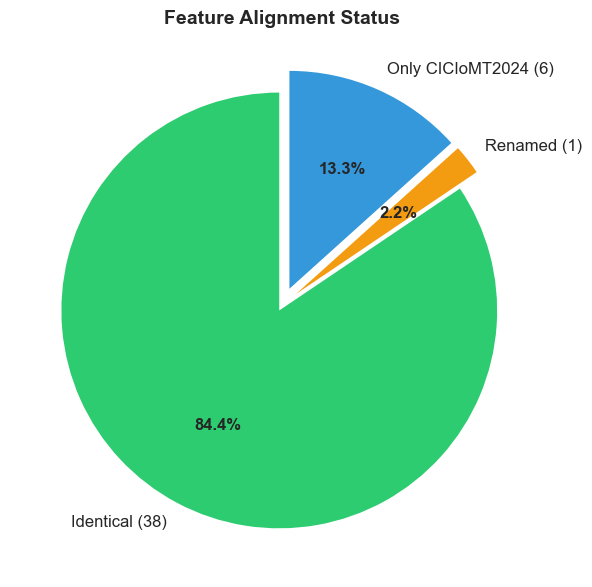

In [10]:
# ══════════════════════════════════════════════════════════════════════
# 5b. Feature alignment summary
# ══════════════════════════════════════════════════════════════════════

n_identical = sum(1 for v in feature_mapping.values() if v['status'] == 'identical')
n_renamed = sum(1 for v in feature_mapping.values() if v['status'] == 'renamed')
n_only_2024 = sum(1 for v in feature_mapping.values() if v['status'] == 'only_2024')

print('Feature Alignment Summary')
print('=' * 50)
print(f'Identical (same name & meaning): {n_identical:>3} features')
print(f'Renamed (different name, same meaning): {n_renamed:>3} feature(s)')
print(f'Only in CICIoMT2024: {n_only_2024:>3} features')
print(f'{"─" * 50}')
print(f'Total alignable features: {n_identical + n_renamed:>3} / {n_identical + n_renamed + n_only_2024}')

print(f'\n{"Implication for Integration":}')
print(f'  → {n_identical + n_renamed} features can be used as unified feature set')
print(f'  → {n_only_2024} extra features (CICIoMT2024 only) will be NaN for CICIoT2023 samples')
print(f'  → TTL mapping: CICIoT2023.Time_To_Live ↔ CICIoMT2024.Duration (rename required)')

# Pie chart
fig, ax = plt.subplots(figsize=(8, 6))
sizes = [n_identical, n_renamed, n_only_2024]
labels_pie = [
    f'Identical ({n_identical})',
    f'Renamed ({n_renamed})',
    f'Only CICIoMT2024 ({n_only_2024})',
]
colors_pie = ['#2ecc71', '#f39c12', '#3498db']
explode = (0.03, 0.08, 0.08)

wedges, texts, autotexts = ax.pie(
    sizes, explode=explode, labels=labels_pie, colors=colors_pie,
    autopct='%1.1f%%', shadow=False, startangle=90,
    textprops={'fontsize': 12}
)
for autotext in autotexts:
    autotext.set_fontweight('bold')

ax.set_title('Feature Alignment Status', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Label Comparison & Attack Taxonomy

Comparison of labels and attack categories between the datasets.

In [11]:
# ══════════════════════════════════════════════════════════════════════
# 6a. Full label inventory for both datasets
# ══════════════════════════════════════════════════════════════════════

# CICIoT2023 label counts
iot2023_label_counts = iot2023_labels['Label'].value_counts()

# CICIoMT2024 label counts
iomt2024_label_counts = iomt2024_labels['label'].value_counts()

print('CICIoT2023 Attack Labels (34)')
print('=' * 60)
for label, count in iot2023_label_counts.items():
    pct = count / iot2023_total_rows * 100
    print(f'  {label:35s} {count:>12,} ({pct:>6.2f}%)')

print(f'\n{"─" * 60}')
print(f'{"TOTAL":35s} {iot2023_total_rows:>12,}')

print(f'\n\nCICIoMT2024 Attack Labels (19)')
print('=' * 60)
for label, count in iomt2024_label_counts.items():
    pct = count / iomt2024_total_rows * 100
    print(f'  {label:35s} {count:>12,} ({pct:>6.2f}%)')

print(f'\n{"─" * 60}')
print(f'{"TOTAL":35s} {iomt2024_total_rows:>12,}')

CICIoT2023 Attack Labels (34)
  DDOS-ICMP_FLOOD                        6,853,894 ( 15.31%)
  DDOS-UDP_FLOOD                         5,151,533 ( 11.51%)
  DDOS-TCP_FLOOD                         4,281,441 (  9.56%)
  DDOS-PSHACK_FLOOD                      3,898,237 (  8.71%)
  DDOS-SYN_FLOOD                         3,864,171 (  8.63%)
  DDOS-RSTFINFLOOD                       3,850,861 (  8.60%)
  DDOS-SYNONYMOUSIP_FLOOD                3,426,081 (  7.65%)
  DOS-UDP_FLOOD                          3,159,007 (  7.06%)
  DOS-TCP_FLOOD                          2,543,792 (  5.68%)
  DOS-SYN_FLOOD                          1,931,122 (  4.31%)
  BENIGN                                 1,045,429 (  2.34%)
  MIRAI-GREETH_FLOOD                       944,055 (  2.11%)
  MIRAI-UDPPLAIN                           847,774 (  1.89%)
  MIRAI-GREIP_FLOOD                        715,488 (  1.60%)
  DDOS-ICMP_FRAGMENTATION                  430,681 (  0.96%)
  VULNERABILITYSCAN                        355,547 (  0

In [12]:
# ══════════════════════════════════════════════════════════════════════
# 6b. Attack category mapping for both datasets
# ══════════════════════════════════════════════════════════════════════

# CICIoT2023 -> category mapping
iot2023_category_map = {
    # Benign
    'BENIGN': 'Benign',
    # DDoS
    'DDOS-ACK_FRAGMENTATION': 'DDoS',
    'DDOS-HTTP_FLOOD': 'DDoS',
    'DDOS-ICMP_FLOOD': 'DDoS',
    'DDOS-ICMP_FRAGMENTATION': 'DDoS',
    'DDOS-PSHACK_FLOOD': 'DDoS',
    'DDOS-RSTFINFLOOD': 'DDoS',
    'DDOS-SLOWLORIS': 'DDoS',
    'DDOS-SYNONYMOUSIP_FLOOD': 'DDoS',
    'DDOS-SYN_FLOOD': 'DDoS',
    'DDOS-TCP_FLOOD': 'DDoS',
    'DDOS-UDP_FLOOD': 'DDoS',
    'DDOS-UDP_FRAGMENTATION': 'DDoS',
    # DoS
    'DOS-HTTP_FLOOD': 'DoS',
    'DOS-SYN_FLOOD': 'DoS',
    'DOS-TCP_FLOOD': 'DoS',
    'DOS-UDP_FLOOD': 'DoS',
    # Mirai
    'MIRAI-GREETH_FLOOD': 'Mirai',
    'MIRAI-GREIP_FLOOD': 'Mirai',
    'MIRAI-UDPPLAIN': 'Mirai',
    # Reconnaissance
    'RECON-HOSTDISCOVERY': 'Reconnaissance',
    'RECON-OSSCAN': 'Reconnaissance',
    'RECON-PINGSWEEP': 'Reconnaissance',
    'RECON-PORTSCAN': 'Reconnaissance',
    'VULNERABILITYSCAN': 'Reconnaissance',
    # Spoofing
    'MITM-ARPSPOOFING': 'Spoofing',
    'DNS_SPOOFING': 'Spoofing',
    # Web-based
    'BROWSERHIJACKING': 'Web-based',
    'COMMANDINJECTION': 'Web-based',
    'SQLINJECTION': 'Web-based',
    'XSS': 'Web-based',
    'UPLOADING_ATTACK': 'Web-based',
    'BACKDOOR_MALWARE': 'Web-based',
    # Brute Force
    'DICTIONARYBRUTEFORCE': 'Brute Force',
}

# CICIoMT2024 -> category mapping
iomt2024_category_map = {
    'Benign': 'Benign',
    # DDoS (TCP/IP)
    'TCP_IP-DDoS-ICMP': 'DDoS',
    'TCP_IP-DDoS-SYN': 'DDoS',
    'TCP_IP-DDoS-TCP': 'DDoS',
    'TCP_IP-DDoS-UDP': 'DDoS',
    # DoS (TCP/IP)
    'TCP_IP-DoS-ICMP': 'DoS',
    'TCP_IP-DoS-SYN': 'DoS',
    'TCP_IP-DoS-TCP': 'DoS',
    'TCP_IP-DoS-UDP': 'DoS',
    # MQTT
    'MQTT-DDoS-Connect_Flood': 'MQTT',
    'MQTT-DDoS-Publish_Flood': 'MQTT',
    'MQTT-DoS-Connect_Flood': 'MQTT',
    'MQTT-DoS-Publish_Flood': 'MQTT',
    'MQTT-Malformed_Data': 'MQTT',
    # Reconnaissance
    'Recon-OS_Scan': 'Reconnaissance',
    'Recon-Ping_Sweep': 'Reconnaissance',
    'Recon-Port_Scan': 'Reconnaissance',
    'Recon-VulScan': 'Reconnaissance',
    # Spoofing
    'ARP_Spoofing': 'Spoofing',
}

# Apply category mapping
iot2023_labels['category'] = iot2023_labels['Label'].map(iot2023_category_map)
iomt2024_labels['category'] = iomt2024_labels['label'].map(iomt2024_category_map)

# Category-level comparison
iot2023_cat_counts = iot2023_labels['category'].value_counts()
iomt2024_cat_counts = iomt2024_labels['category'].value_counts()

all_categories = sorted(set(iot2023_cat_counts.index) | set(iomt2024_cat_counts.index))

print('Attack Category Comparison')
print('=' * 80)
print(f'{"Category":20s} | {"CICIoT2023":>15s} {"(%)":>7s} | {"CICIoMT2024":>15s} {"(%)":>7s} | Overlap')
print('─' * 80)

for cat in all_categories:
    c1 = iot2023_cat_counts.get(cat, 0)
    c2 = iomt2024_cat_counts.get(cat, 0)
    p1 = c1 / iot2023_total_rows * 100 if c1 > 0 else 0
    p2 = c2 / iomt2024_total_rows * 100 if c2 > 0 else 0
    overlap = '✓ Both' if c1 > 0 and c2 > 0 else ('IoT only' if c2 == 0 else 'IoMT only')
    print(f'{cat:20s} | {c1:>15,} {p1:>6.1f}% | {c2:>15,} {p2:>6.1f}% | {overlap}')

print('─' * 80)
print(f'{"TOTAL":20s} | {iot2023_total_rows:>15,} {100.0:>6.1f}% | {iomt2024_total_rows:>15,} {100.0:>6.1f}% |')

Attack Category Comparison
Category             |      CICIoT2023     (%) |     CICIoMT2024     (%) | Overlap
────────────────────────────────────────────────────────────────────────────────
Benign               |       1,045,429    2.3% |         133,197    1.6% | ✓ Both
Brute Force          |          12,442    0.0% |               0    0.0% | IoT only
DDoS                 |      32,351,222   72.3% |       5,546,412   66.6% | ✓ Both
DoS                  |       7,702,337   17.2% |       2,222,205   26.7% | ✓ Both
MQTT                 |               0    0.0% |         271,889    3.3% | IoMT only
Mirai                |       2,507,317    5.6% |               0    0.0% | IoT only
Reconnaissance       |         657,397    1.5% |         131,402    1.6% | ✓ Both
Spoofing             |         463,333    1.0% |          17,791    0.2% | ✓ Both
Web-based            |          23,656    0.1% |               0    0.0% | IoT only
──────────────────────────────────────────────────────────────

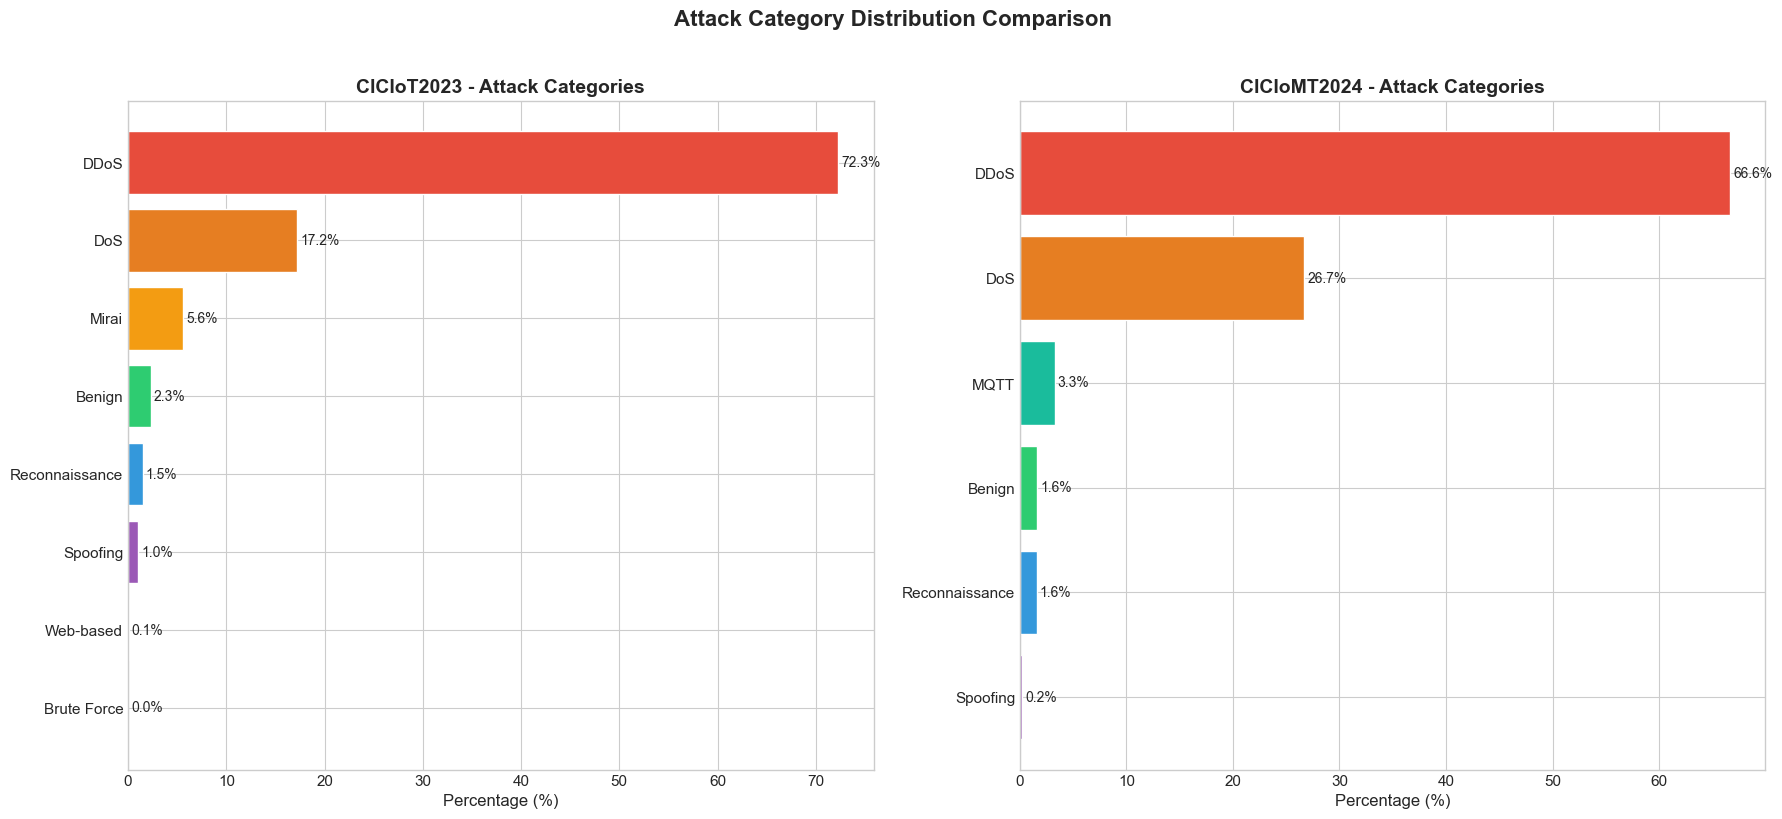

In [13]:
# ══════════════════════════════════════════════════════════════════════
# 6c. Visual: side-by-side category distribution
# ══════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ── CICIoT2023 ──
cat_order_2023 = iot2023_cat_counts.index.tolist()
colors_2023 = [CATEGORY_COLORS.get(c, '#95a5a6') for c in cat_order_2023]
pct_2023 = (iot2023_cat_counts / iot2023_total_rows * 100)

bars1 = axes[0].barh(cat_order_2023, pct_2023, color=colors_2023, edgecolor='white')
axes[0].set_xlabel('Percentage (%)')
axes[0].set_title('CICIoT2023 - Attack Categories', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()
for bar, pct in zip(bars1, pct_2023):
    axes[0].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{pct:.1f}%', va='center', fontsize=10)

# ── CICIoMT2024 ──
cat_order_2024 = iomt2024_cat_counts.index.tolist()
colors_2024 = [CATEGORY_COLORS.get(c, '#95a5a6') for c in cat_order_2024]
pct_2024 = (iomt2024_cat_counts / iomt2024_total_rows * 100)

bars2 = axes[1].barh(cat_order_2024, pct_2024, color=colors_2024, edgecolor='white')
axes[1].set_xlabel('Percentage (%)')
axes[1].set_title('CICIoMT2024 - Attack Categories', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()
for bar, pct in zip(bars2, pct_2024):
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{pct:.1f}%', va='center', fontsize=10)

plt.suptitle('Attack Category Distribution Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# ══════════════════════════════════════════════════════════════════════
# 6d. Overlap analysis: which attack sub-types are shared?
# ══════════════════════════════════════════════════════════════════════

# Define semantic mapping between individual attack labels
attack_overlap_map = {
    # ── Overlapping attacks (similar type, different naming) ──
    'DDoS - SYN Flood':   {'CICIoT2023': 'DDOS-SYN_FLOOD',          'CICIoMT2024': 'TCP_IP-DDoS-SYN'},
    'DDoS - TCP Flood':   {'CICIoT2023': 'DDOS-TCP_FLOOD',          'CICIoMT2024': 'TCP_IP-DDoS-TCP'},
    'DDoS - UDP Flood':   {'CICIoT2023': 'DDOS-UDP_FLOOD',          'CICIoMT2024': 'TCP_IP-DDoS-UDP'},
    'DDoS - ICMP Flood':  {'CICIoT2023': 'DDOS-ICMP_FLOOD',         'CICIoMT2024': 'TCP_IP-DDoS-ICMP'},
    'DoS - SYN Flood':    {'CICIoT2023': 'DOS-SYN_FLOOD',           'CICIoMT2024': 'TCP_IP-DoS-SYN'},
    'DoS - TCP Flood':    {'CICIoT2023': 'DOS-TCP_FLOOD',           'CICIoMT2024': 'TCP_IP-DoS-TCP'},
    'DoS - UDP Flood':    {'CICIoT2023': 'DOS-UDP_FLOOD',           'CICIoMT2024': 'TCP_IP-DoS-UDP'},
    'DoS - ICMP Flood':   {'CICIoT2023': None,                      'CICIoMT2024': 'TCP_IP-DoS-ICMP'},
    'Recon - OS Scan':    {'CICIoT2023': 'RECON-OSSCAN',            'CICIoMT2024': 'Recon-OS_Scan'},
    'Recon - Ping Sweep': {'CICIoT2023': 'RECON-PINGSWEEP',         'CICIoMT2024': 'Recon-Ping_Sweep'},
    'Recon - Port Scan':  {'CICIoT2023': 'RECON-PORTSCAN',          'CICIoMT2024': 'Recon-Port_Scan'},
    'Recon - Vuln Scan':  {'CICIoT2023': 'VULNERABILITYSCAN',       'CICIoMT2024': 'Recon-VulScan'},
    'ARP Spoofing':       {'CICIoT2023': 'MITM-ARPSPOOFING',        'CICIoMT2024': 'ARP_Spoofing'},
}

print('Attack Sub-type Overlap Analysis')
print('=' * 90)
print(f'{"Unified Attack":22s} | {"CICIoT2023 Label":28s} | {"CICIoMT2024 Label":28s} | Status')
print('─' * 90)

both_count = 0
for unified, mapping in attack_overlap_map.items():
    c2023 = mapping['CICIoT2023'] or '—'
    c2024 = mapping['CICIoMT2024'] or '—'
    if mapping['CICIoT2023'] and mapping['CICIoMT2024']:
        status = '✓ Both'
        both_count += 1
    elif mapping['CICIoT2023']:
        status = 'IoT only'
    else:
        status = 'IoMT only'
    print(f'{unified:22s} | {c2023:28s} | {c2024:28s} | {status}')

print(f'\n{"─" * 90}')

# Additional unique labels not in overlap map
mapped_2023 = {v['CICIoT2023'] for v in attack_overlap_map.values() if v['CICIoT2023']}
mapped_2024 = {v['CICIoMT2024'] for v in attack_overlap_map.values() if v['CICIoMT2024']}

unmapped_2023 = sorted(set(iot2023_label_counts.index) - mapped_2023)
unmapped_2024 = sorted(set(iomt2024_label_counts.index) - mapped_2024)

print(f'\nAttacks ONLY in CICIoT2023 ({len(unmapped_2023)}):')
for label in unmapped_2023:
    cat = iot2023_category_map.get(label, 'Unknown')
    count = iot2023_label_counts[label]
    print(f'  [{cat:15s}] {label:30s} ({count:>10,} rows)')

print(f'\nAttacks ONLY in CICIoMT2024 ({len(unmapped_2024)}):')
for label in unmapped_2024:
    cat = iomt2024_category_map.get(label, 'Unknown')
    count = iomt2024_label_counts[label]
    print(f'  [{cat:15s}] {label:30s} ({count:>10,} rows)')

Attack Sub-type Overlap Analysis
Unified Attack         | CICIoT2023 Label             | CICIoMT2024 Label            | Status
──────────────────────────────────────────────────────────────────────────────────────────
DDoS - SYN Flood       | DDOS-SYN_FLOOD               | TCP_IP-DDoS-SYN              | ✓ Both
DDoS - TCP Flood       | DDOS-TCP_FLOOD               | TCP_IP-DDoS-TCP              | ✓ Both
DDoS - UDP Flood       | DDOS-UDP_FLOOD               | TCP_IP-DDoS-UDP              | ✓ Both
DDoS - ICMP Flood      | DDOS-ICMP_FLOOD              | TCP_IP-DDoS-ICMP             | ✓ Both
DoS - SYN Flood        | DOS-SYN_FLOOD                | TCP_IP-DoS-SYN               | ✓ Both
DoS - TCP Flood        | DOS-TCP_FLOOD                | TCP_IP-DoS-TCP               | ✓ Both
DoS - UDP Flood        | DOS-UDP_FLOOD                | TCP_IP-DoS-UDP               | ✓ Both
DoS - ICMP Flood       | —                            | TCP_IP-DoS-ICMP              | IoMT only
Recon - OS Scan        | RE

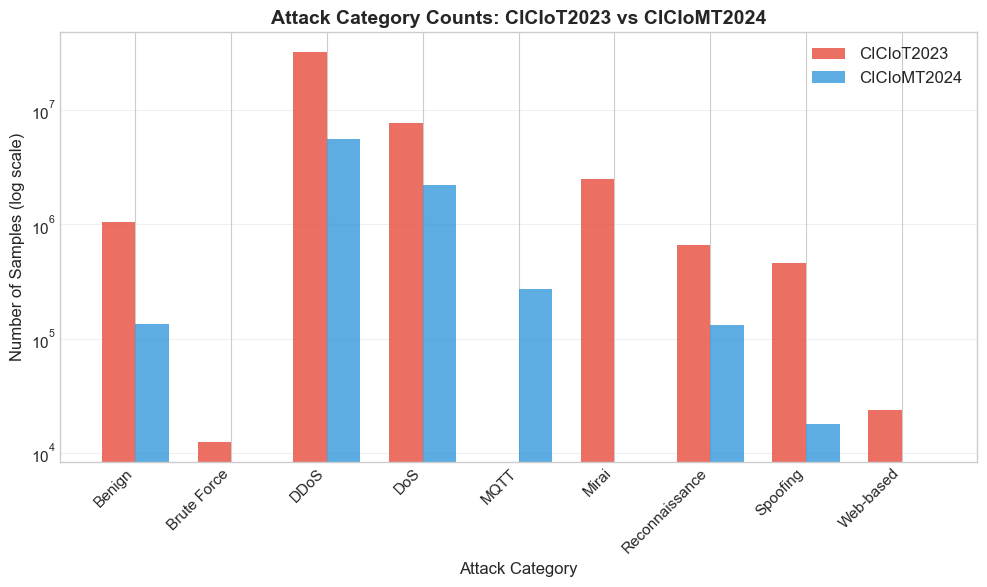

In [15]:
# ══════════════════════════════════════════════════════════════════════
# 6e. Visual: attack overlap heatmap-style matrix
# ══════════════════════════════════════════════════════════════════════

# Prepare data for overlap visualization
all_2023_labels = sorted(iot2023_label_counts.index)
all_2024_labels = sorted(iomt2024_label_counts.index)

# Create overlap presence matrix
overlap_categories = sorted(set(iot2023_cat_counts.index) | set(iomt2024_cat_counts.index))

fig, ax = plt.subplots(figsize=(10, 6))

# Build grouped bar data
x = np.arange(len(overlap_categories))
width = 0.35

counts_2023 = [iot2023_cat_counts.get(c, 0) for c in overlap_categories]
counts_2024 = [iomt2024_cat_counts.get(c, 0) for c in overlap_categories]

# Use log scale for better visibility (counts differ by orders of magnitude)
bars1 = ax.bar(x - width/2, counts_2023, width, label='CICIoT2023', color='#e74c3c', alpha=0.8)
bars2 = ax.bar(x + width/2, counts_2024, width, label='CICIoMT2024', color='#3498db', alpha=0.8)

ax.set_xlabel('Attack Category')
ax.set_ylabel('Number of Samples (log scale)')
ax.set_title('Attack Category Counts: CICIoT2023 vs CICIoMT2024', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(overlap_categories, rotation=45, ha='right')
ax.set_yscale('log')
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Label Harmonization Proposal

### Label Unification Proposal

For creating a unified dataset, we need **three classification levels** (classification levels).

In [16]:
# ══════════════════════════════════════════════════════════════════════
# 7a. Unified label taxonomy (3 levels)
# ══════════════════════════════════════════════════════════════════════

# Level 1: Binary (Benign / Attack)
# Level 2: Category (Benign, DDoS, DoS, Recon, Spoofing, MQTT, Mirai, Web-based, Brute Force)
# Level 3: Fine-grained (unified attack names)

unified_taxonomy = {
    # ── CICIoT2023 labels ──
    'BENIGN':                   {'binary': 'Benign',  'category': 'Benign',          'unified': 'Benign'},
    'DDOS-SYN_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SYN_Flood'},
    'DDOS-TCP_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-TCP_Flood'},
    'DDOS-UDP_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Flood'},
    'DDOS-ICMP_FLOOD':          {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Flood'},
    'DDOS-ACK_FRAGMENTATION':   {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ACK_Fragmentation'},
    'DDOS-HTTP_FLOOD':          {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-HTTP_Flood'},
    'DDOS-ICMP_FRAGMENTATION':  {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Fragmentation'},
    'DDOS-PSHACK_FLOOD':        {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-PSHACK_Flood'},
    'DDOS-RSTFINFLOOD':         {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-RSTFIN_Flood'},
    'DDOS-SLOWLORIS':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-Slowloris'},
    'DDOS-SYNONYMOUSIP_FLOOD':  {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SynonymousIP_Flood'},
    'DDOS-UDP_FRAGMENTATION':   {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Fragmentation'},
    'DOS-SYN_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-SYN_Flood'},
    'DOS-TCP_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-TCP_Flood'},
    'DOS-UDP_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-UDP_Flood'},
    'DOS-HTTP_FLOOD':           {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-HTTP_Flood'},
    'MIRAI-GREETH_FLOOD':       {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-GREETH_Flood'},
    'MIRAI-GREIP_FLOOD':        {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-GREIP_Flood'},
    'MIRAI-UDPPLAIN':           {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-UDPPlain'},
    'RECON-HOSTDISCOVERY':      {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Host_Discovery'},
    'RECON-OSSCAN':             {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-OS_Scan'},
    'RECON-PINGSWEEP':          {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Ping_Sweep'},
    'RECON-PORTSCAN':           {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Port_Scan'},
    'VULNERABILITYSCAN':        {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Vuln_Scan'},
    'MITM-ARPSPOOFING':        {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'ARP_Spoofing'},
    'DNS_SPOOFING':             {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'DNS_Spoofing'},
    'BROWSERHIJACKING':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-BrowserHijacking'},
    'COMMANDINJECTION':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-CommandInjection'},
    'SQLINJECTION':             {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-SQLInjection'},
    'XSS':                      {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-XSS'},
    'UPLOADING_ATTACK':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-UploadingAttack'},
    'BACKDOOR_MALWARE':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-BackdoorMalware'},
    'DICTIONARYBRUTEFORCE':     {'binary': 'Attack',  'category': 'Brute Force',      'unified': 'BruteForce-Dictionary'},
    
    # ── CICIoMT2024 labels ──
    'Benign':                      {'binary': 'Benign',  'category': 'Benign',          'unified': 'Benign'},
    'TCP_IP-DDoS-SYN':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SYN_Flood'},
    'TCP_IP-DDoS-TCP':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-TCP_Flood'},
    'TCP_IP-DDoS-UDP':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Flood'},
    'TCP_IP-DDoS-ICMP':            {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Flood'},
    'TCP_IP-DoS-SYN':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-SYN_Flood'},
    'TCP_IP-DoS-TCP':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-TCP_Flood'},
    'TCP_IP-DoS-UDP':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-UDP_Flood'},
    'TCP_IP-DoS-ICMP':             {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-ICMP_Flood'},
    'MQTT-DDoS-Connect_Flood':     {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DDoS-Connect_Flood'},
    'MQTT-DDoS-Publish_Flood':     {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DDoS-Publish_Flood'},
    'MQTT-DoS-Connect_Flood':      {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DoS-Connect_Flood'},
    'MQTT-DoS-Publish_Flood':      {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DoS-Publish_Flood'},
    'MQTT-Malformed_Data':         {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-Malformed_Data'},
    'Recon-OS_Scan':               {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-OS_Scan'},
    'Recon-Ping_Sweep':            {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Ping_Sweep'},
    'Recon-Port_Scan':             {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Port_Scan'},
    'Recon-VulScan':               {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Vuln_Scan'},
    'ARP_Spoofing':                {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'ARP_Spoofing'},
}

# Display the taxonomy
print('Unified Label Taxonomy (3 levels)')
print('=' * 100)
print(f'{"Original Label":35s} | {"Binary":8s} | {"Category":15s} | {"Unified Fine-grained":30s} | Source')
print('─' * 100)

# Show CICIoT2023 labels first
iot2023_originals = sorted(iot2023_label_counts.index)
iomt2024_originals = sorted(iomt2024_label_counts.index)

print('  --- CICIoT2023 ---')
for label in iot2023_originals:
    info = unified_taxonomy[label]
    print(f'{label:35s} | {info["binary"]:8s} | {info["category"]:15s} | {info["unified"]:30s} | IoT2023')

print(f'\n  --- CICIoMT2024 ---')
for label in iomt2024_originals:
    info = unified_taxonomy[label]
    print(f'{label:35s} | {info["binary"]:8s} | {info["category"]:15s} | {info["unified"]:30s} | IoMT2024')

Unified Label Taxonomy (3 levels)
Original Label                      | Binary   | Category        | Unified Fine-grained           | Source
────────────────────────────────────────────────────────────────────────────────────────────────────
  --- CICIoT2023 ---
BACKDOOR_MALWARE                    | Attack   | Web-based       | Web-BackdoorMalware            | IoT2023
BENIGN                              | Benign   | Benign          | Benign                         | IoT2023
BROWSERHIJACKING                    | Attack   | Web-based       | Web-BrowserHijacking           | IoT2023
COMMANDINJECTION                    | Attack   | Web-based       | Web-CommandInjection           | IoT2023
DDOS-ACK_FRAGMENTATION              | Attack   | DDoS            | DDoS-ACK_Fragmentation         | IoT2023
DDOS-HTTP_FLOOD                     | Attack   | DDoS            | DDoS-HTTP_Flood                | IoT2023
DDOS-ICMP_FLOOD                     | Attack   | DDoS            | DDoS-ICMP_Flood       

In [17]:
# ══════════════════════════════════════════════════════════════════════
# 7b. Classification level summary
# ══════════════════════════════════════════════════════════════════════

# Count unique unified labels
all_unified = set()
all_categories_unified = set()
for info in unified_taxonomy.values():
    all_unified.add(info['unified'])
    all_categories_unified.add(info['category'])

# Determine which unified labels come from which dataset
unified_from_2023 = set()
unified_from_2024 = set()
for label in iot2023_originals:
    unified_from_2023.add(unified_taxonomy[label]['unified'])
for label in iomt2024_originals:
    unified_from_2024.add(unified_taxonomy[label]['unified'])

shared_unified = unified_from_2023 & unified_from_2024
only_from_2023 = unified_from_2023 - unified_from_2024
only_from_2024 = unified_from_2024 - unified_from_2023

print('Unified Taxonomy Summary')
print('=' * 60)
print(f'Level 1 (Binary):      2 classes (Benign / Attack)')
print(f'Level 2 (Category):    {len(all_categories_unified)} classes')
print(f'Level 3 (Fine-grained): {len(all_unified)} unique attack types')

print(f'\nFine-grained label overlap:')
print(f'  Shared (both datasets):    {len(shared_unified):>3} labels')
print(f'  Only CICIoT2023:           {len(only_from_2023):>3} labels')
print(f'  Only CICIoMT2024:          {len(only_from_2024):>3} labels')

print(f'\nShared attack types ({len(shared_unified)}):')
for label in sorted(shared_unified):
    print(f'  ✓ {label}')

print(f'\nOnly in CICIoT2023 ({len(only_from_2023)}):')
for label in sorted(only_from_2023):
    print(f'  ◆ {label}')

print(f'\nOnly in CICIoMT2024 ({len(only_from_2024)}):')
for label in sorted(only_from_2024):
    print(f'  ★ {label}')

Unified Taxonomy Summary
Level 1 (Binary):      2 classes (Benign / Attack)
Level 2 (Category):    9 classes
Level 3 (Fine-grained): 40 unique attack types

Fine-grained label overlap:
  Shared (both datasets):     13 labels
  Only CICIoT2023:            21 labels
  Only CICIoMT2024:            6 labels

Shared attack types (13):
  ✓ ARP_Spoofing
  ✓ Benign
  ✓ DDoS-ICMP_Flood
  ✓ DDoS-SYN_Flood
  ✓ DDoS-TCP_Flood
  ✓ DDoS-UDP_Flood
  ✓ DoS-SYN_Flood
  ✓ DoS-TCP_Flood
  ✓ DoS-UDP_Flood
  ✓ Recon-OS_Scan
  ✓ Recon-Ping_Sweep
  ✓ Recon-Port_Scan
  ✓ Recon-Vuln_Scan

Only in CICIoT2023 (21):
  ◆ BruteForce-Dictionary
  ◆ DDoS-ACK_Fragmentation
  ◆ DDoS-HTTP_Flood
  ◆ DDoS-ICMP_Fragmentation
  ◆ DDoS-PSHACK_Flood
  ◆ DDoS-RSTFIN_Flood
  ◆ DDoS-Slowloris
  ◆ DDoS-SynonymousIP_Flood
  ◆ DDoS-UDP_Fragmentation
  ◆ DNS_Spoofing
  ◆ DoS-HTTP_Flood
  ◆ Mirai-GREETH_Flood
  ◆ Mirai-GREIP_Flood
  ◆ Mirai-UDPPlain
  ◆ Recon-Host_Discovery
  ◆ Web-BackdoorMalware
  ◆ Web-BrowserHijacking
  ◆ Web-Com

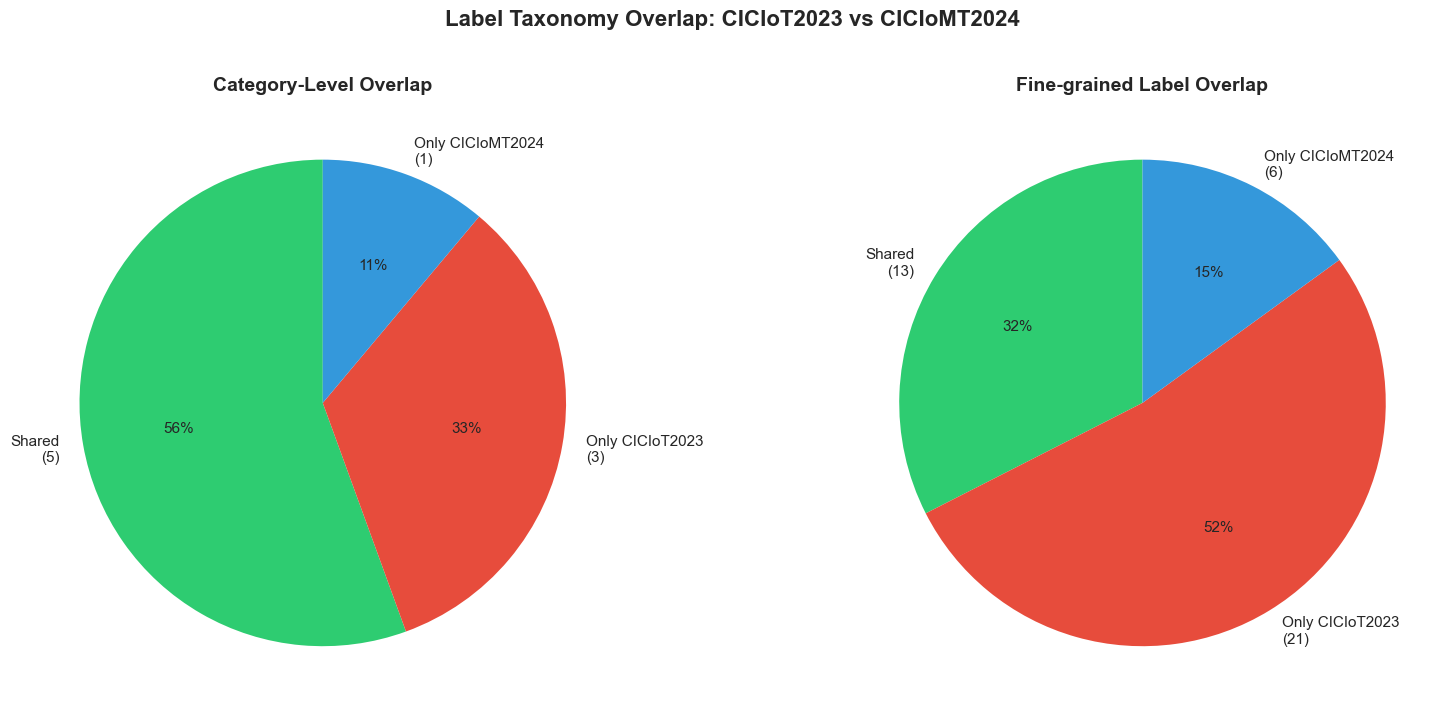

In [18]:
# ══════════════════════════════════════════════════════════════════════
# 7c. Visual: unified taxonomy overlap
# ══════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── Left: Category-level overlap ──
cat_2023_only = set(iot2023_cat_counts.index) - set(iomt2024_cat_counts.index)
cat_2024_only = set(iomt2024_cat_counts.index) - set(iot2023_cat_counts.index)
cat_shared = set(iot2023_cat_counts.index) & set(iomt2024_cat_counts.index)

cat_data = [
    ('Shared', len(cat_shared)),
    ('Only CICIoT2023', len(cat_2023_only)),
    ('Only CICIoMT2024', len(cat_2024_only)),
]
cat_labels_pie = [f'{name}\n({count})' for name, count in cat_data]
cat_sizes = [count for _, count in cat_data]
cat_colors = ['#2ecc71', '#e74c3c', '#3498db']

axes[0].pie(cat_sizes, labels=cat_labels_pie, colors=cat_colors,
            autopct='%1.0f%%', startangle=90, textprops={'fontsize': 11})
axes[0].set_title('Category-Level Overlap', fontsize=14, fontweight='bold')

# ── Right: Fine-grained overlap ──
fg_data = [
    ('Shared', len(shared_unified)),
    ('Only CICIoT2023', len(only_from_2023)),
    ('Only CICIoMT2024', len(only_from_2024)),
]
fg_labels_pie = [f'{name}\n({count})' for name, count in fg_data]
fg_sizes = [count for _, count in fg_data]

axes[1].pie(fg_sizes, labels=fg_labels_pie, colors=cat_colors,
            autopct='%1.0f%%', startangle=90, textprops={'fontsize': 11})
axes[1].set_title('Fine-grained Label Overlap', fontsize=14, fontweight='bold')

plt.suptitle('Label Taxonomy Overlap: CICIoT2023 vs CICIoMT2024', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Statistical Comparison of Common Features

Comparison of distributions of common features between the two datasets.  
We use the samples (~500K rows/dataset) loaded in step 3.

In [19]:
# ══════════════════════════════════════════════════════════════════════
# 8a. Basic statistics comparison (mean, std, min, max, skewness)
# ══════════════════════════════════════════════════════════════════════

# Align TTL column names for comparison
# CICIoT2023: Time_To_Live, CICIoMT2024: Duration (both = TTL)
# We'll compare them as the same feature

# Define common features for comparison (including the TTL mapping)
compare_features = [
    ('Header_Length', 'Header_Length', 'Header_Length'),
    ('Protocol Type', 'Protocol Type', 'Protocol Type'),
    ('Time_To_Live', 'Duration', 'TTL'),  # renamed
    ('Rate', 'Rate', 'Rate'),
    ('fin_flag_number', 'fin_flag_number', 'fin_flag_number'),
    ('syn_flag_number', 'syn_flag_number', 'syn_flag_number'),
    ('rst_flag_number', 'rst_flag_number', 'rst_flag_number'),
    ('psh_flag_number', 'psh_flag_number', 'psh_flag_number'),
    ('ack_flag_number', 'ack_flag_number', 'ack_flag_number'),
    ('ack_count', 'ack_count', 'ack_count'),
    ('syn_count', 'syn_count', 'syn_count'),
    ('fin_count', 'fin_count', 'fin_count'),
    ('rst_count', 'rst_count', 'rst_count'),
    ('HTTP', 'HTTP', 'HTTP'),
    ('HTTPS', 'HTTPS', 'HTTPS'),
    ('DNS', 'DNS', 'DNS'),
    ('TCP', 'TCP', 'TCP'),
    ('UDP', 'UDP', 'UDP'),
    ('ICMP', 'ICMP', 'ICMP'),
    ('ARP', 'ARP', 'ARP'),
    ('Tot sum', 'Tot sum', 'Tot sum'),
    ('Min', 'Min', 'Min'),
    ('Max', 'Max', 'Max'),
    ('AVG', 'AVG', 'AVG'),
    ('Std', 'Std', 'Std'),
    ('Tot size', 'Tot size', 'Tot size'),
    ('IAT', 'IAT', 'IAT'),
    ('Number', 'Number', 'Number'),
    ('Variance', 'Variance', 'Variance'),
]

print('Statistical Comparison of Common Features (sampled data)')
print('=' * 120)
print(f'{"Feature":20s} | {"CICIoT2023 Mean":>16s} {"Std":>12s} | {"CICIoMT2024 Mean":>16s} {"Std":>12s} | {"Mean Delta%":>10s} | {"KS Note":>10s}')
print('─' * 120)

comparison_stats = []
for col_2023, col_2024, display_name in compare_features:
    s2023 = df_sample_2023[col_2023].replace([np.inf, -np.inf], np.nan).dropna()
    s2024 = df_sample_2024[col_2024].replace([np.inf, -np.inf], np.nan).dropna()
    
    mean_2023 = s2023.mean()
    std_2023 = s2023.std()
    mean_2024 = s2024.mean()
    std_2024 = s2024.std()
    
    # Mean difference percentage
    if abs(mean_2023) > 1e-10:
        mean_diff_pct = (mean_2024 - mean_2023) / abs(mean_2023) * 100
    else:
        mean_diff_pct = 0.0 if abs(mean_2024) < 1e-10 else float('inf')
    
    # Flag large differences
    flag = '◄ LARGE' if abs(mean_diff_pct) > 50 and abs(mean_diff_pct) != float('inf') else ''
    
    comparison_stats.append({
        'feature': display_name,
        'mean_2023': mean_2023, 'std_2023': std_2023,
        'mean_2024': mean_2024, 'std_2024': std_2024,
        'mean_diff_pct': mean_diff_pct,
    })
    
    if abs(mean_diff_pct) == float('inf'):
        diff_str = '     inf'
    else:
        diff_str = f'{mean_diff_pct:>+10.1f}%'
    
    print(f'{display_name:20s} | {mean_2023:>16.4f} {std_2023:>12.4f} | {mean_2024:>16.4f} {std_2024:>12.4f} | {diff_str} | {flag}')

Statistical Comparison of Common Features (sampled data)
Feature              |  CICIoT2023 Mean          Std | CICIoMT2024 Mean          Std | Mean Delta% |    KS Note
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Header_Length        |          13.7249       8.7350 |       83639.8624  565154.1845 |  +609301.5% | ◄ LARGE
Protocol Type        |           9.0662       9.0845 |           7.5456       5.7215 |      -16.8% | 
TTL                  |          66.5255      14.4395 |          64.9789      12.7671 |       -2.3% | 
Rate                 |       28463.5286   32009.8045 |       12227.2952   35794.8711 |      -57.0% | ◄ LARGE
fin_flag_number      |           0.0863       0.2784 |           0.0083       0.0407 |      -90.4% | ◄ LARGE
syn_flag_number      |           0.2071       0.3999 |           0.1688       0.3403 |      -18.5% | 
rst_flag_number      |           0.0924       0.2825 |           0.0638       0.1885 |      -31.0% | 
psh_flag_number      |           0.0943       0.2775 |           0.0571       0.1531 |      -39.4% | 
ack_flag_number      |           0.1299       0.3166 |           0.1948       0.3544 |      +50.0% | 
ack_count            |           9.8834      28.0576 |       

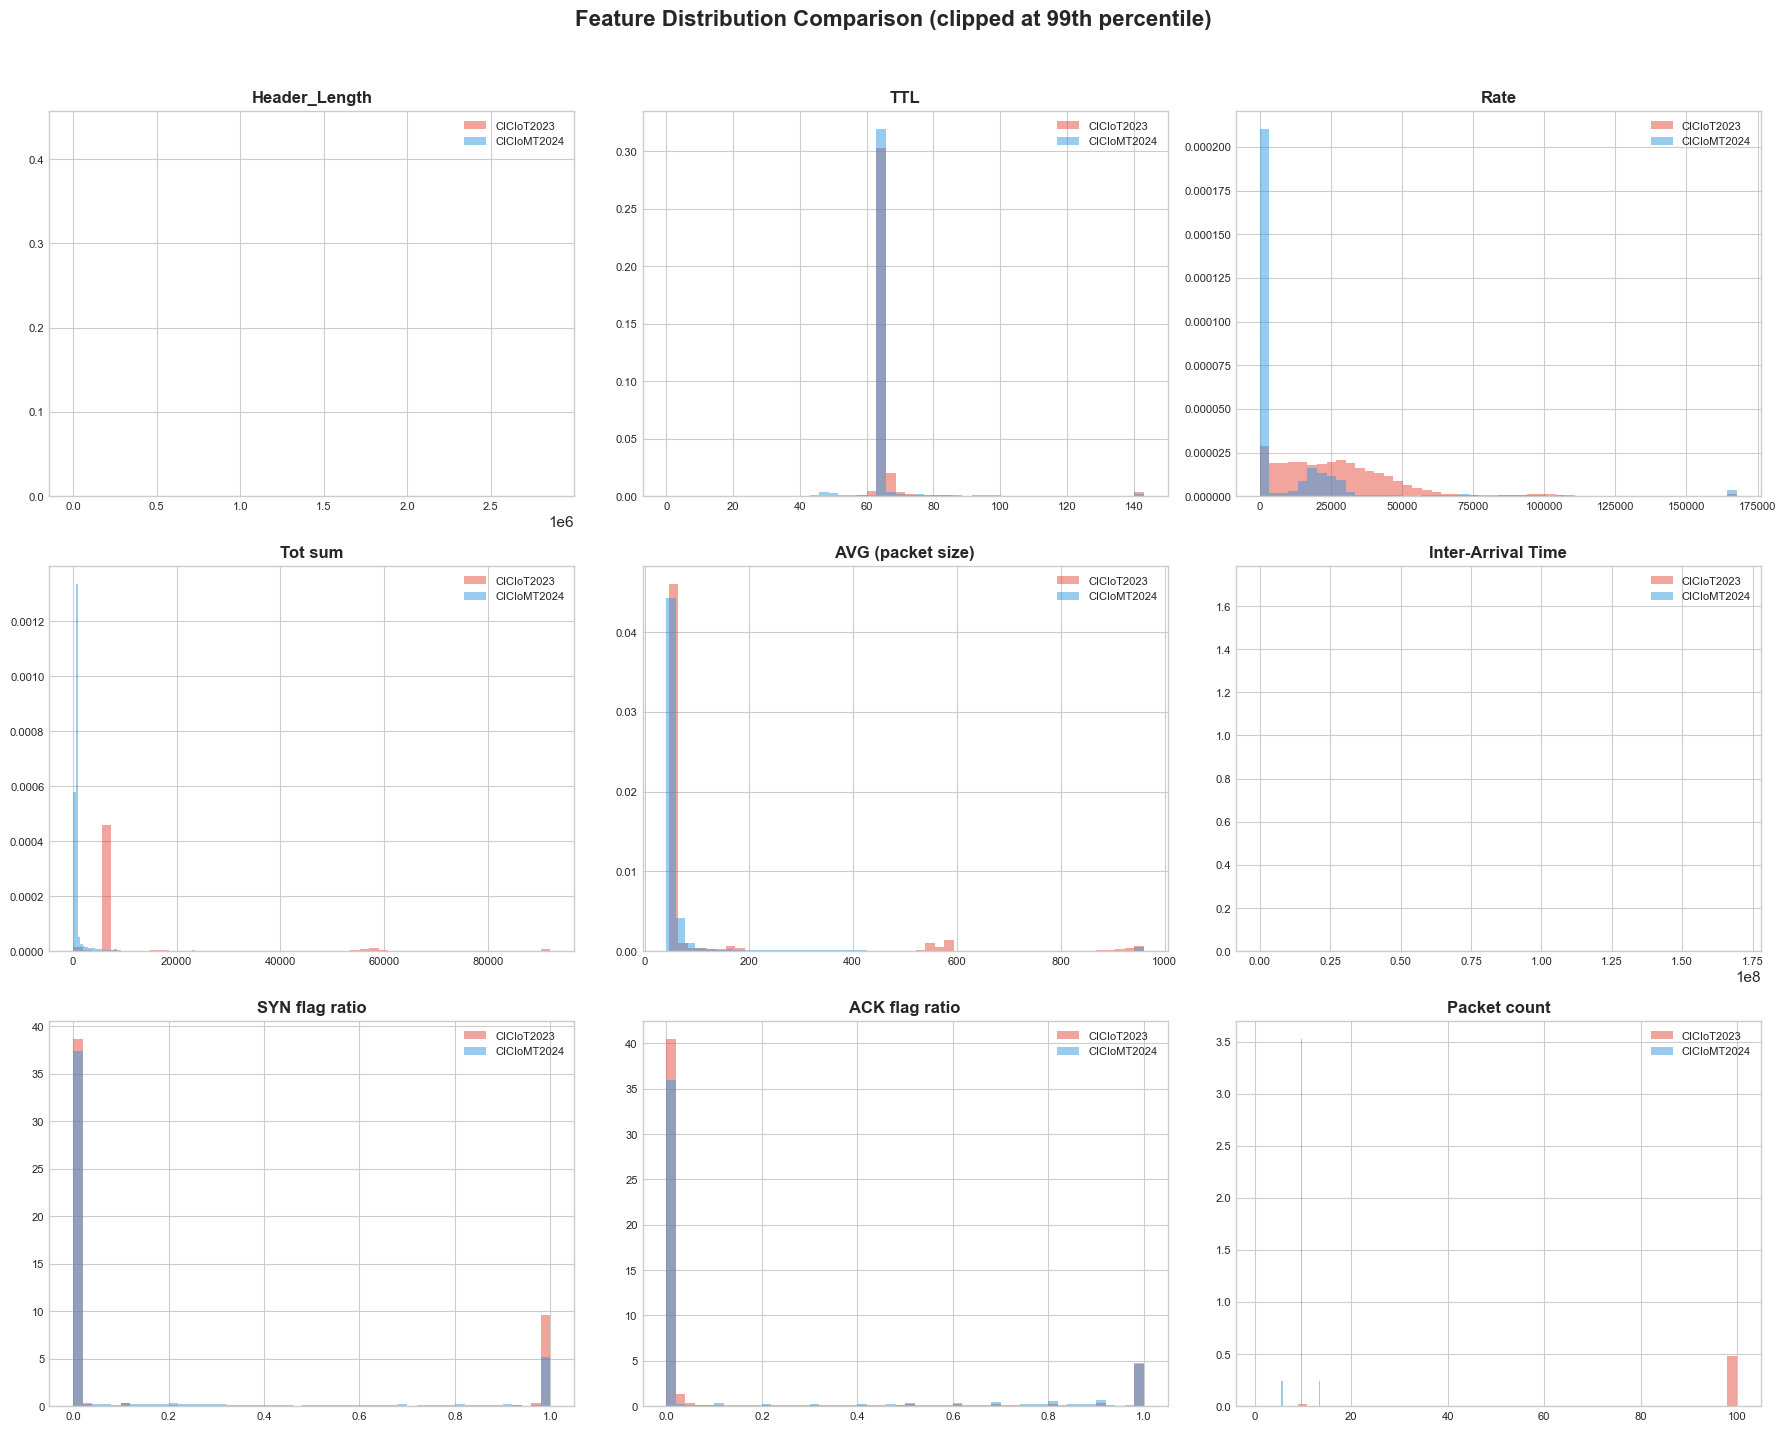

In [20]:
# ══════════════════════════════════════════════════════════════════════
# 8b. Visual: distribution comparison for key features
# ══════════════════════════════════════════════════════════════════════

# Select a representative subset of features for visualization
key_features = [
    ('Header_Length', 'Header_Length', 'Header_Length'),
    ('Time_To_Live', 'Duration', 'TTL'),
    ('Rate', 'Rate', 'Rate'),
    ('Tot sum', 'Tot sum', 'Tot sum'),
    ('AVG', 'AVG', 'AVG (packet size)'),
    ('IAT', 'IAT', 'Inter-Arrival Time'),
    ('syn_flag_number', 'syn_flag_number', 'SYN flag ratio'),
    ('ack_flag_number', 'ack_flag_number', 'ACK flag ratio'),
    ('Number', 'Number', 'Packet count'),
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, (col_2023, col_2024, display_name) in enumerate(key_features):
    ax = axes[idx]
    
    s2023 = df_sample_2023[col_2023].replace([np.inf, -np.inf], np.nan).dropna()
    s2024 = df_sample_2024[col_2024].replace([np.inf, -np.inf], np.nan).dropna()
    
    # Clip extreme outliers for better visualization
    q99_2023 = s2023.quantile(0.99)
    q99_2024 = s2024.quantile(0.99)
    clip_max = max(q99_2023, q99_2024)
    
    s2023_clipped = s2023.clip(upper=clip_max)
    s2024_clipped = s2024.clip(upper=clip_max)
    
    ax.hist(s2023_clipped, bins=50, alpha=0.5, color='#e74c3c', label='CICIoT2023', density=True)
    ax.hist(s2024_clipped, bins=50, alpha=0.5, color='#3498db', label='CICIoMT2024', density=True)
    
    ax.set_title(display_name, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)

plt.suptitle('Feature Distribution Comparison (clipped at 99th percentile)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

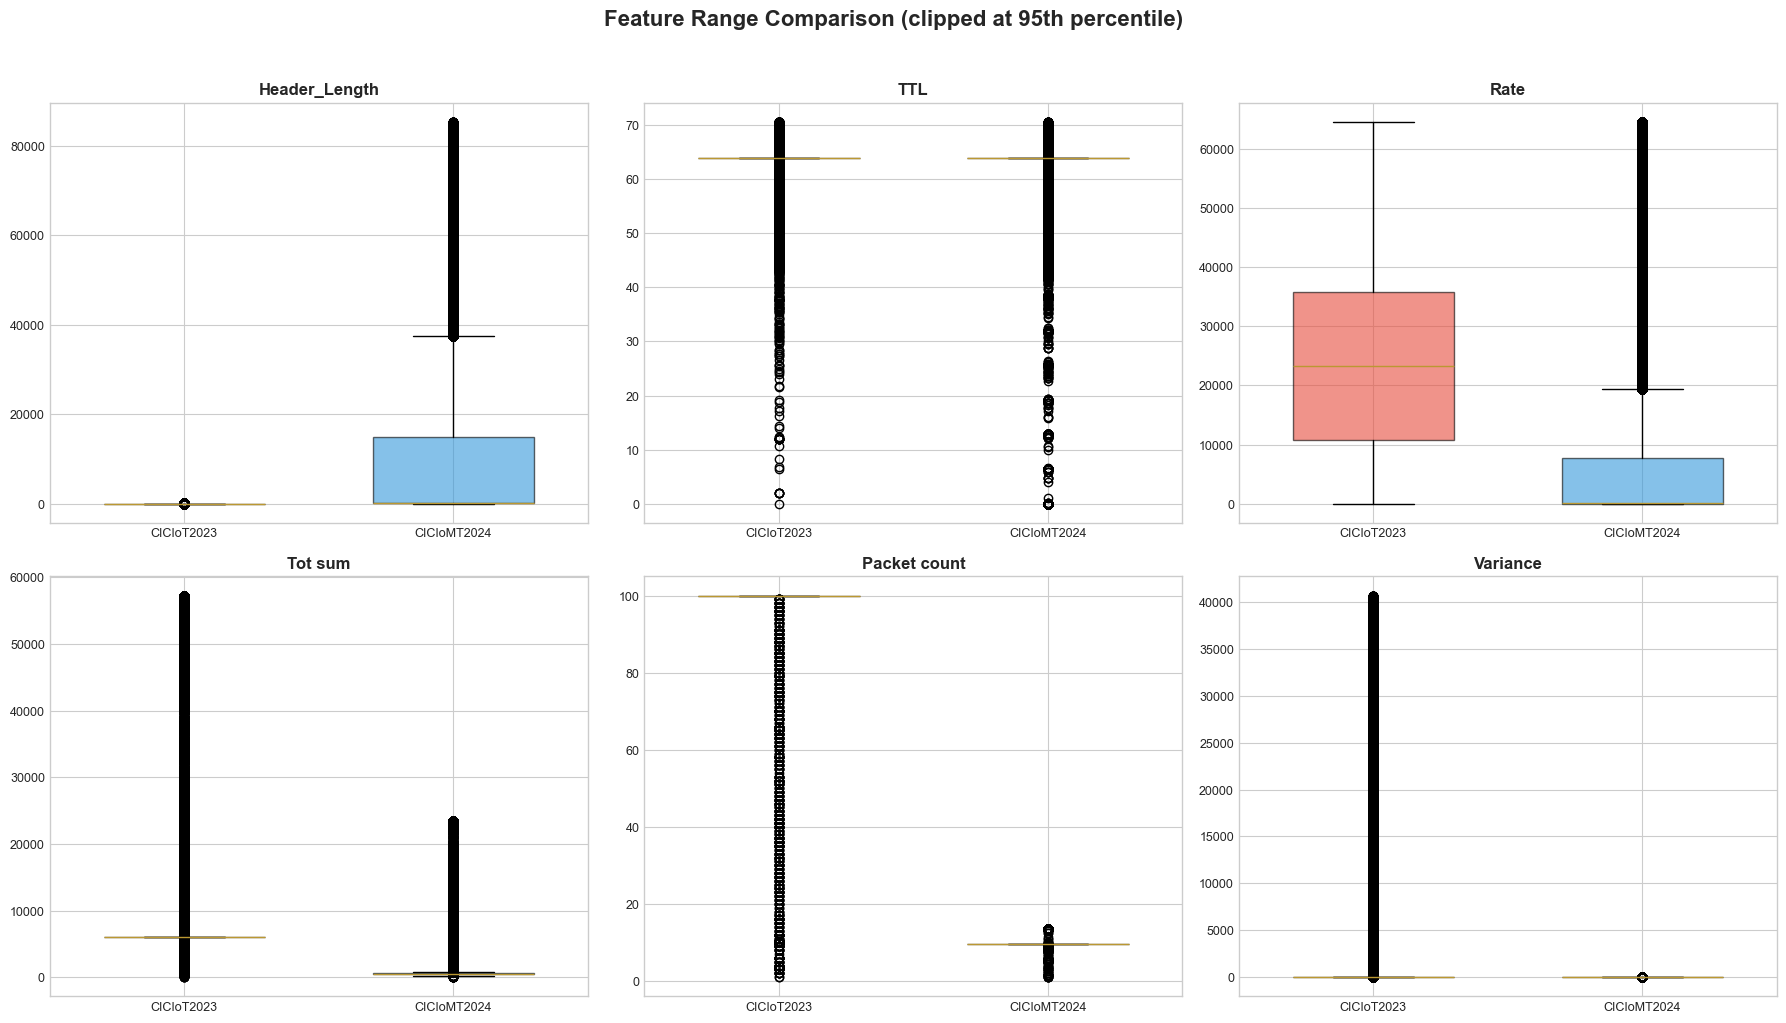

In [21]:
# ══════════════════════════════════════════════════════════════════════
# 8c. Box plot comparison for selected features
# ══════════════════════════════════════════════════════════════════════

box_features = [
    ('Header_Length', 'Header_Length', 'Header_Length'),
    ('Time_To_Live', 'Duration', 'TTL'),
    ('Rate', 'Rate', 'Rate'),
    ('Tot sum', 'Tot sum', 'Tot sum'),
    ('Number', 'Number', 'Packet count'),
    ('Variance', 'Variance', 'Variance'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (col_2023, col_2024, display_name) in enumerate(box_features):
    ax = axes[idx]
    
    s2023 = df_sample_2023[col_2023].replace([np.inf, -np.inf], np.nan).dropna()
    s2024 = df_sample_2024[col_2024].replace([np.inf, -np.inf], np.nan).dropna()
    
    # Clip for visualization
    q95_2023 = s2023.quantile(0.95)
    q95_2024 = s2024.quantile(0.95)
    clip_max = max(q95_2023, q95_2024)
    if clip_max == 0:
        clip_max = max(s2023.max(), s2024.max())
    
    data_to_plot = [
        s2023[s2023 <= clip_max],
        s2024[s2024 <= clip_max],
    ]
    
    bp = ax.boxplot(data_to_plot, labels=['CICIoT2023', 'CICIoMT2024'],
                    patch_artist=True, widths=0.6)
    bp['boxes'][0].set_facecolor('#e74c3c')
    bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor('#3498db')
    bp['boxes'][1].set_alpha(0.6)
    
    ax.set_title(display_name, fontsize=12, fontweight='bold')
    ax.tick_params(labelsize=9)

plt.suptitle('Feature Range Comparison (clipped at 95th percentile)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

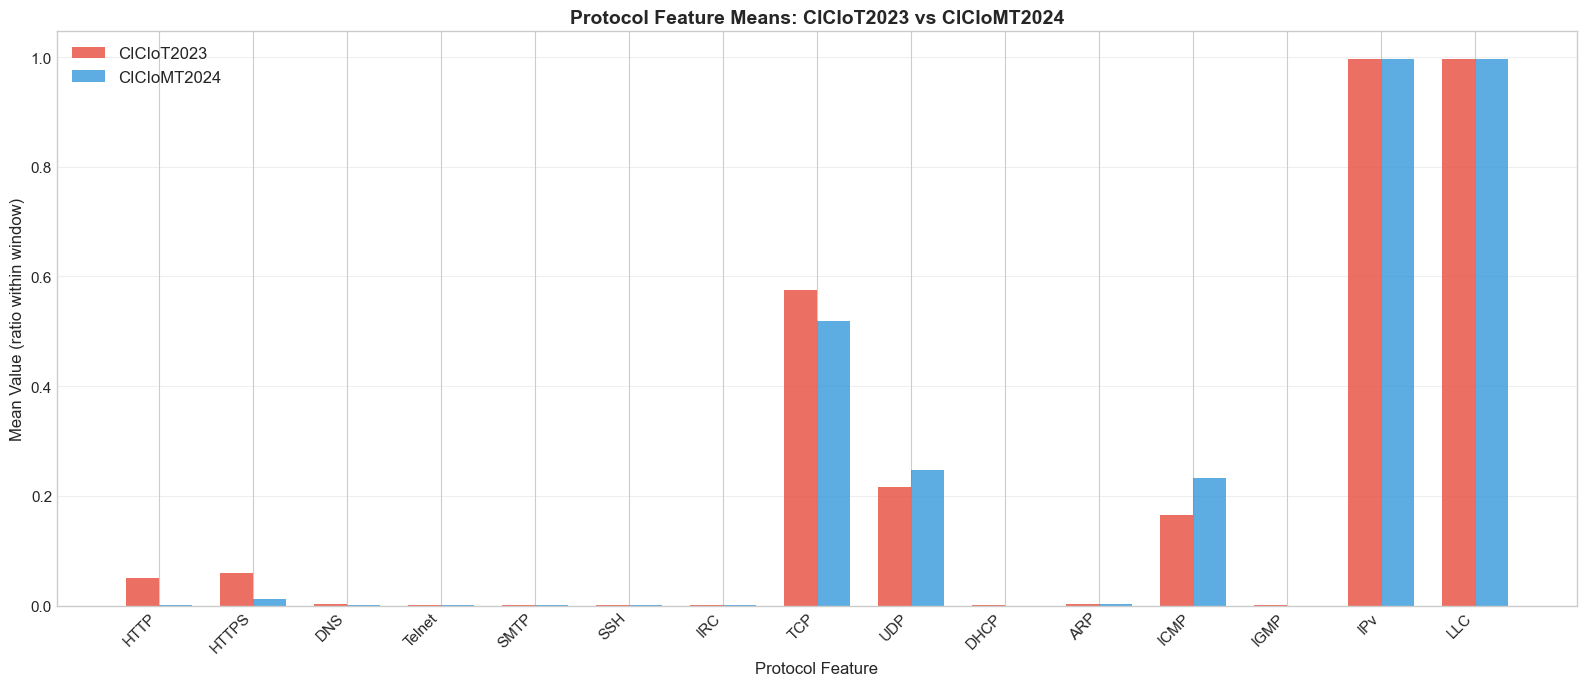

In [22]:
# ══════════════════════════════════════════════════════════════════════
# 8d. Protocol feature comparison (binary protocol indicators)
# ══════════════════════════════════════════════════════════════════════

protocol_features = ['HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC',
                      'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC']

proto_means_2023 = []
proto_means_2024 = []

for p in protocol_features:
    proto_means_2023.append(df_sample_2023[p].mean())
    proto_means_2024.append(df_sample_2024[p].mean())

fig, ax = plt.subplots(figsize=(16, 7))

x = np.arange(len(protocol_features))
width = 0.35

bars1 = ax.bar(x - width/2, proto_means_2023, width, label='CICIoT2023',
               color='#e74c3c', alpha=0.8)
bars2 = ax.bar(x + width/2, proto_means_2024, width, label='CICIoMT2024',
               color='#3498db', alpha=0.8)

ax.set_xlabel('Protocol Feature')
ax.set_ylabel('Mean Value (ratio within window)')
ax.set_title('Protocol Feature Means: CICIoT2023 vs CICIoMT2024', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(protocol_features, rotation=45, ha='right')
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Scale & Class Imbalance Comparison

Comparison of scale, class ratios, and class imbalance between datasets.

Scale Comparison
Metric                         |      CICIoT2023 |     CICIoMT2024 | Ratio
──────────────────────────────────────────────────────────────────────
Total rows                     |      44,763,144 |       8,322,896 | 5.4x
Number of CSV files            |              63 |              72 | 0.9x
Feature columns                |              39 |              45 | 0.9x
Unique labels (fine-grained)   |              34 |              19 | 1.8x
Attack categories              |               7 |               5 | 1.4x


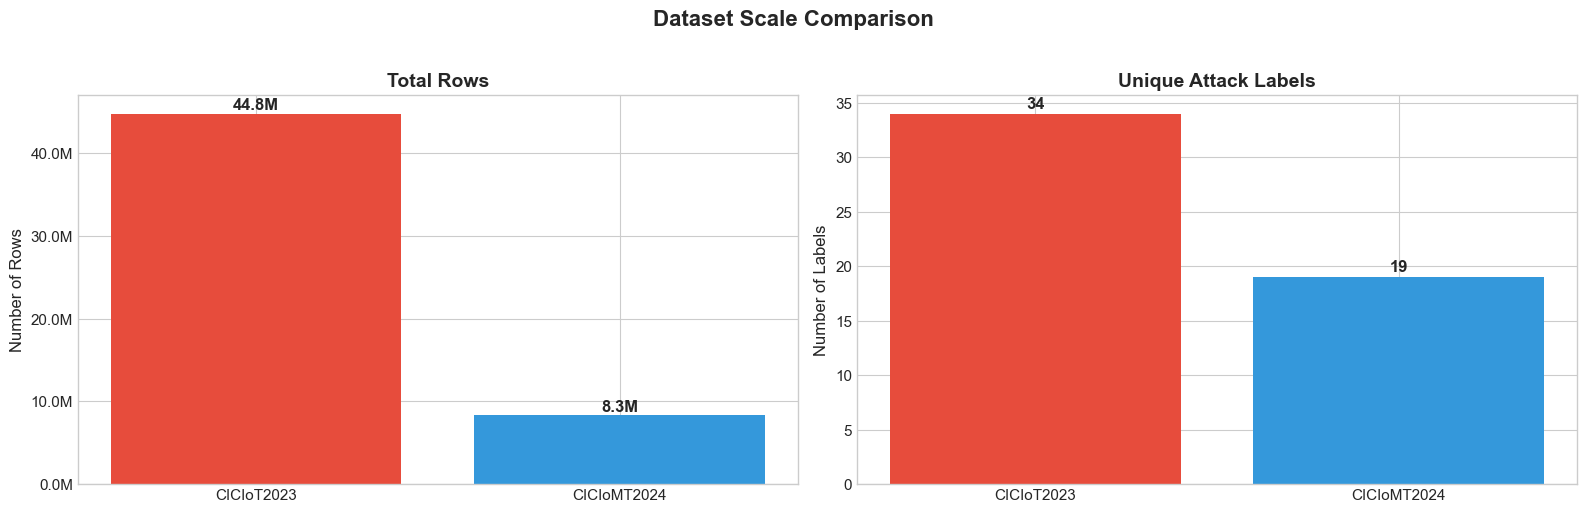

In [23]:
# ══════════════════════════════════════════════════════════════════════
# 9a. Scale comparison overview
# ══════════════════════════════════════════════════════════════════════

print('Scale Comparison')
print('=' * 70)
print(f'{"Metric":30s} | {"CICIoT2023":>15s} | {"CICIoMT2024":>15s} | Ratio')
print('─' * 70)

iot2023_n_features = len(iot2023_all_cols) - 1  # exclude Label
iomt2024_n_features = len(iomt2024_all_cols)

metrics = [
    ('Total rows', iot2023_total_rows, iomt2024_total_rows),
    ('Number of CSV files', len(iot2023_files), len(iomt2024_train_files) + len(iomt2024_test_files)),
    ('Feature columns', iot2023_n_features, iomt2024_n_features),
    ('Unique labels (fine-grained)', iot2023_labels['Label'].nunique(), iomt2024_labels['label'].nunique()),
    ('Attack categories', len(set(iot2023_category_map.values())) - 1, len(set(iomt2024_category_map.values())) - 1),  # -1 for Benign
]

for name, v2023, v2024 in metrics:
    ratio = v2023 / v2024 if v2024 > 0 else float('inf')
    print(f'{name:30s} | {v2023:>15,} | {v2024:>15,} | {ratio:.1f}x')

# Scale comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Row counts
axes[0].bar(['CICIoT2023', 'CICIoMT2024'],
            [iot2023_total_rows, iomt2024_total_rows],
            color=[DATASET_COLORS['CICIoT2023'], DATASET_COLORS['CICIoMT2024']])
axes[0].set_ylabel('Number of Rows')
axes[0].set_title('Total Rows', fontsize=14, fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f}M'))
for i, v in enumerate([iot2023_total_rows, iomt2024_total_rows]):
    axes[0].text(i, v + 500000, f'{v/1e6:.1f}M', ha='center', fontweight='bold', fontsize=12)

# Label counts
axes[1].bar(['CICIoT2023', 'CICIoMT2024'],
            [iot2023_labels['Label'].nunique(), iomt2024_labels['label'].nunique()],
            color=[DATASET_COLORS['CICIoT2023'], DATASET_COLORS['CICIoMT2024']])
axes[1].set_ylabel('Number of Labels')
axes[1].set_title('Unique Attack Labels', fontsize=14, fontweight='bold')
for i, v in enumerate([iot2023_labels['Label'].nunique(), iomt2024_labels['label'].nunique()]):
    axes[1].text(i, v + 0.5, str(v), ha='center', fontweight='bold', fontsize=12)

plt.suptitle('Dataset Scale Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [24]:
# ══════════════════════════════════════════════════════════════════════
# 9b. Class imbalance analysis
# ══════════════════════════════════════════════════════════════════════

print('Class Imbalance Analysis')
print('=' * 70)

# Binary level imbalance
iot2023_benign = iot2023_label_counts.get('BENIGN', 0)
iot2023_attack = iot2023_total_rows - iot2023_benign
iomt2024_benign = iomt2024_label_counts.get('Benign', 0)
iomt2024_attack = iomt2024_total_rows - iomt2024_benign

print('\nBinary Level (Benign vs Attack):')
print(f'  CICIoT2023:  Benign={iot2023_benign:>10,} ({iot2023_benign/iot2023_total_rows*100:.1f}%)  |  Attack={iot2023_attack:>12,} ({iot2023_attack/iot2023_total_rows*100:.1f}%)  |  Ratio 1:{iot2023_attack/iot2023_benign:.0f}')
print(f'  CICIoMT2024: Benign={iomt2024_benign:>10,} ({iomt2024_benign/iomt2024_total_rows*100:.1f}%)  |  Attack={iomt2024_attack:>12,} ({iomt2024_attack/iomt2024_total_rows*100:.1f}%)  |  Ratio 1:{iomt2024_attack/iomt2024_benign:.0f}')

# Fine-grained level imbalance
print('\nFine-grained Level (min vs max class):')
iot2023_min_label = iot2023_label_counts.idxmin()
iot2023_max_label = iot2023_label_counts.idxmax()
iot2023_min_count = iot2023_label_counts.min()
iot2023_max_count = iot2023_label_counts.max()

iomt2024_min_label = iomt2024_label_counts.idxmin()
iomt2024_max_label = iomt2024_label_counts.idxmax()
iomt2024_min_count = iomt2024_label_counts.min()
iomt2024_max_count = iomt2024_label_counts.max()

print(f'  CICIoT2023:  Min={iot2023_min_label} ({iot2023_min_count:,})  |  Max={iot2023_max_label} ({iot2023_max_count:,})  |  Imbalance ratio: 1:{iot2023_max_count/iot2023_min_count:.0f}')
print(f'  CICIoMT2024: Min={iomt2024_min_label} ({iomt2024_min_count:,})  |  Max={iomt2024_max_label} ({iomt2024_max_count:,})  |  Imbalance ratio: 1:{iomt2024_max_count/iomt2024_min_count:.0f}')

Class Imbalance Analysis

Binary Level (Benign vs Attack):
  CICIoT2023:  Benign= 1,045,429 (2.3%)  |  Attack=  43,717,715 (97.7%)  |  Ratio 1:42
  CICIoMT2024: Benign=   133,197 (1.6%)  |  Attack=   8,189,699 (98.4%)  |  Ratio 1:61

Fine-grained Level (min vs max class):
  CICIoT2023:  Min=UPLOADING_ATTACK (1,192)  |  Max=DDOS-ICMP_FLOOD (6,853,894)  |  Imbalance ratio: 1:5750
  CICIoMT2024: Min=Recon-Ping_Sweep (926)  |  Max=TCP_IP-DDoS-UDP (1,998,026)  |  Imbalance ratio: 1:2158


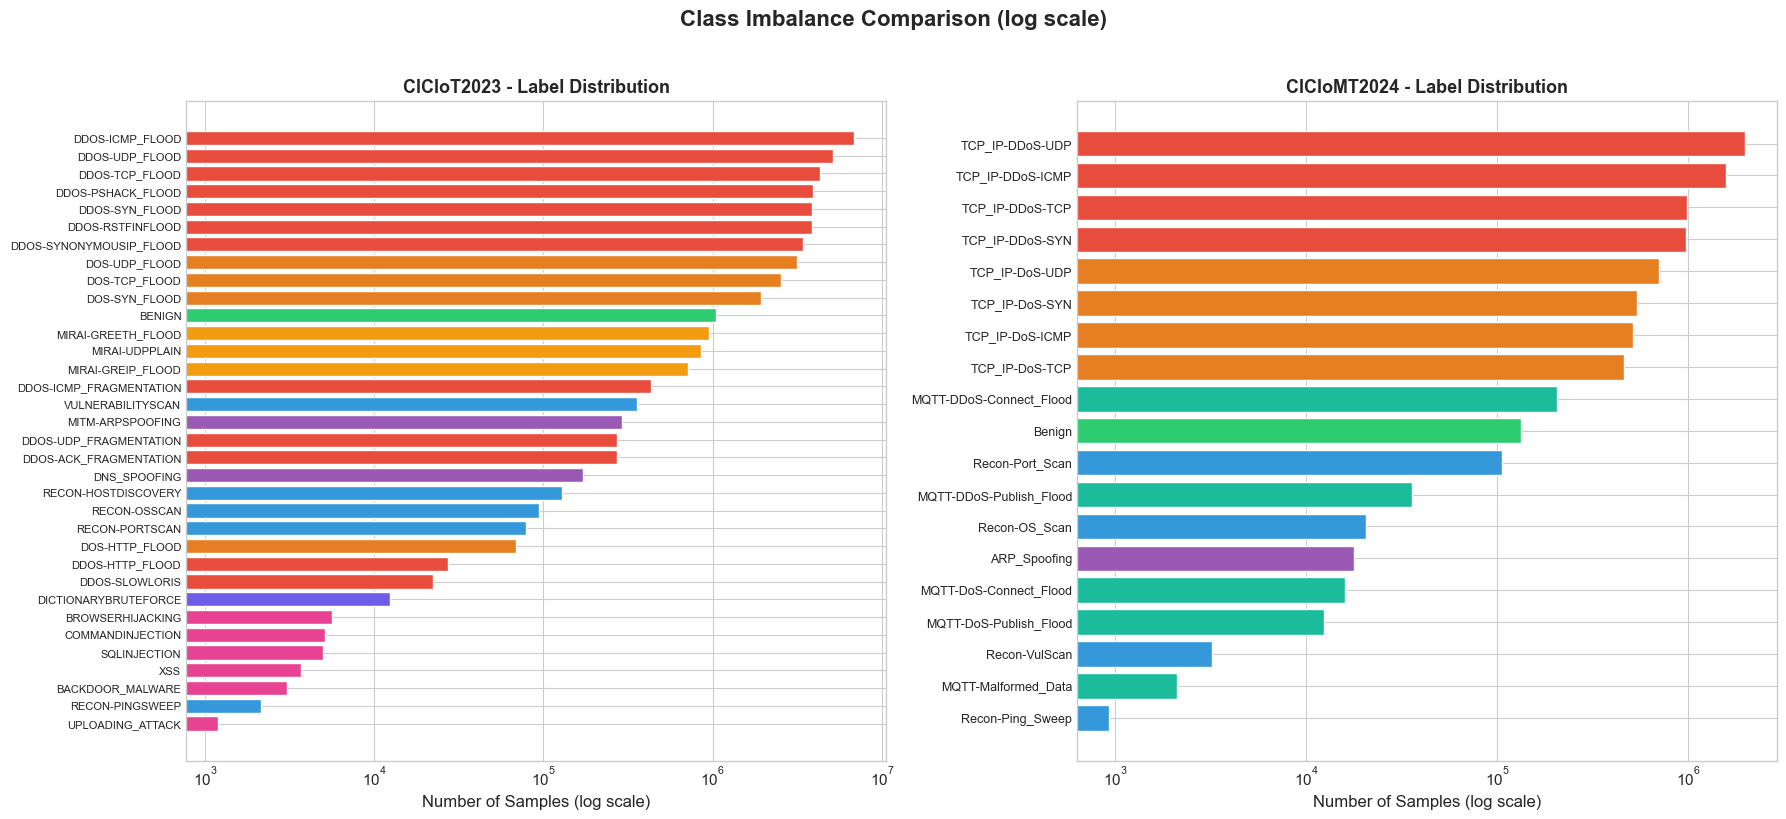

In [25]:
# ══════════════════════════════════════════════════════════════════════
# 9c. Visual: class imbalance comparison
# ══════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ── CICIoT2023 label distribution (log scale) ──
labels_2023 = iot2023_label_counts.index.tolist()
counts_2023 = iot2023_label_counts.values
colors_2023 = [CATEGORY_COLORS.get(iot2023_category_map.get(l, ''), '#95a5a6') for l in labels_2023]

axes[0].barh(labels_2023, counts_2023, color=colors_2023, edgecolor='white')
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of Samples (log scale)')
axes[0].set_title('CICIoT2023 - Label Distribution', fontsize=13, fontweight='bold')
axes[0].invert_yaxis()
axes[0].tick_params(axis='y', labelsize=8)

# ── CICIoMT2024 label distribution (log scale) ──
labels_2024 = iomt2024_label_counts.index.tolist()
counts_2024 = iomt2024_label_counts.values
colors_2024 = [CATEGORY_COLORS.get(iomt2024_category_map.get(l, ''), '#95a5a6') for l in labels_2024]

axes[1].barh(labels_2024, counts_2024, color=colors_2024, edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_xlabel('Number of Samples (log scale)')
axes[1].set_title('CICIoMT2024 - Label Distribution', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()
axes[1].tick_params(axis='y', labelsize=9)

plt.suptitle('Class Imbalance Comparison (log scale)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Shared Attack Types: Sample Count Comparison
Unified Name         |   CICIoT2023 |  CICIoMT2024 |      Ratio
────────────────────────────────────────────────────────────────────────────────
DDoS-SYN Flood       |    3,864,171 |      974,359 |      4.0x
DDoS-TCP Flood       |    4,281,441 |      987,063 |      4.3x
DDoS-UDP Flood       |    5,151,533 |    1,998,026 |      2.6x
DDoS-ICMP Flood      |    6,853,894 |    1,586,964 |      4.3x
DoS-SYN Flood        |    1,931,122 |      540,498 |      3.6x
DoS-TCP Flood        |    2,543,792 |      462,480 |      5.5x
DoS-UDP Flood        |    3,159,007 |      704,503 |      4.5x
Recon-OS Scan        |       93,463 |       20,666 |      4.5x
Recon-Ping Sweep     |        2,147 |          926 |      2.3x
Recon-Port Scan      |       78,299 |      106,603 |      0.7x
Recon-Vuln Scan      |      355,547 |        3,207 |    110.9x
ARP Spoofing         |      292,817 |       17,791 |     16.5x
Benign               |    1,045,429 |      133,197 |  

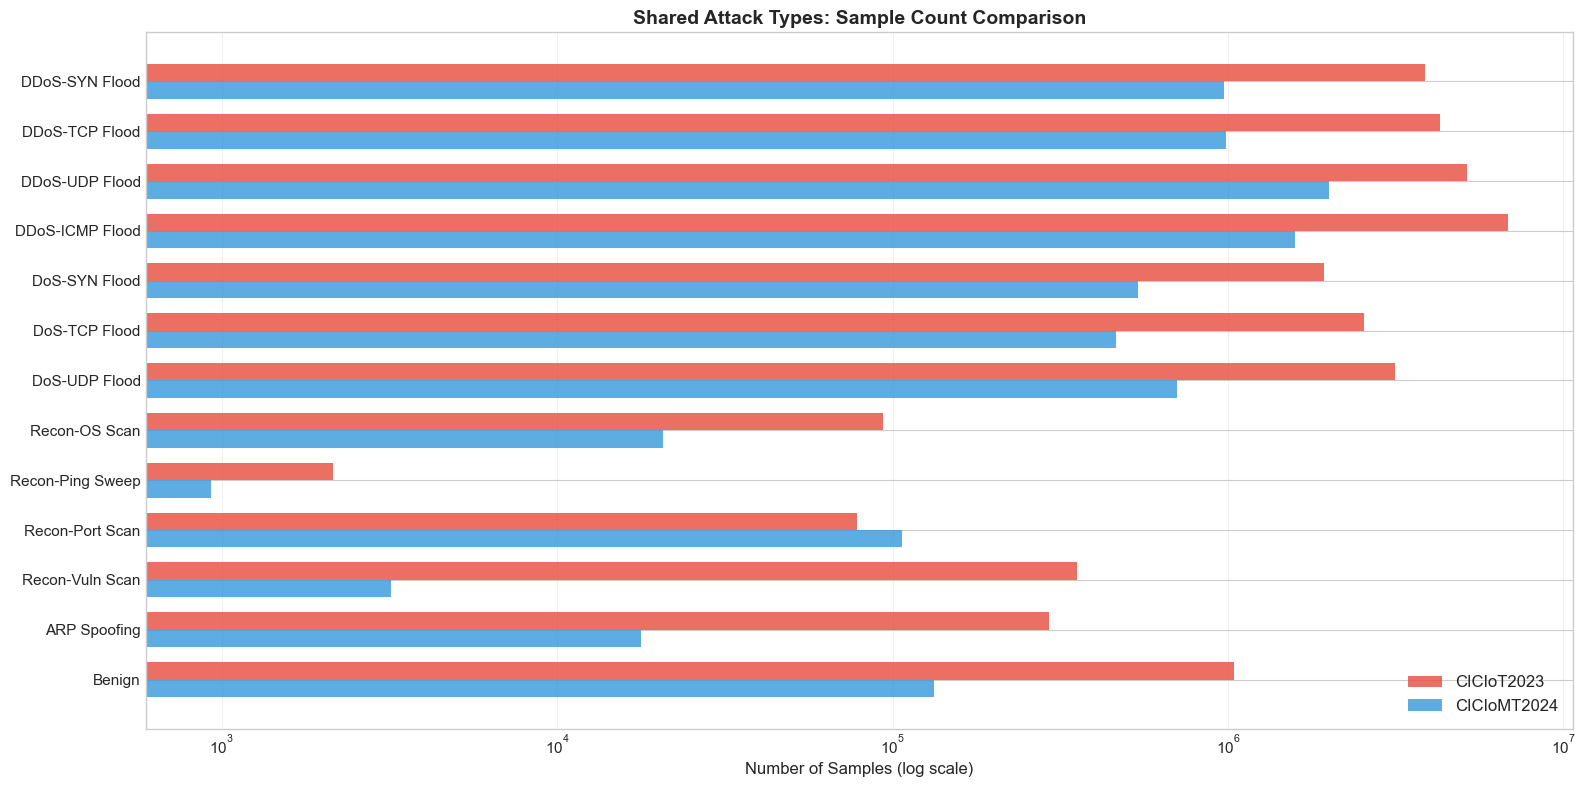

In [26]:
# ══════════════════════════════════════════════════════════════════════
# 9d. Shared attack types: sample count comparison
# ══════════════════════════════════════════════════════════════════════

# Compare sample counts for overlapping attack types
shared_attacks = [
    ('DDoS-SYN Flood', 'DDOS-SYN_FLOOD', 'TCP_IP-DDoS-SYN'),
    ('DDoS-TCP Flood', 'DDOS-TCP_FLOOD', 'TCP_IP-DDoS-TCP'),
    ('DDoS-UDP Flood', 'DDOS-UDP_FLOOD', 'TCP_IP-DDoS-UDP'),
    ('DDoS-ICMP Flood', 'DDOS-ICMP_FLOOD', 'TCP_IP-DDoS-ICMP'),
    ('DoS-SYN Flood', 'DOS-SYN_FLOOD', 'TCP_IP-DoS-SYN'),
    ('DoS-TCP Flood', 'DOS-TCP_FLOOD', 'TCP_IP-DoS-TCP'),
    ('DoS-UDP Flood', 'DOS-UDP_FLOOD', 'TCP_IP-DoS-UDP'),
    ('Recon-OS Scan', 'RECON-OSSCAN', 'Recon-OS_Scan'),
    ('Recon-Ping Sweep', 'RECON-PINGSWEEP', 'Recon-Ping_Sweep'),
    ('Recon-Port Scan', 'RECON-PORTSCAN', 'Recon-Port_Scan'),
    ('Recon-Vuln Scan', 'VULNERABILITYSCAN', 'Recon-VulScan'),
    ('ARP Spoofing', 'MITM-ARPSPOOFING', 'ARP_Spoofing'),
    ('Benign', 'BENIGN', 'Benign'),
]

print('Shared Attack Types: Sample Count Comparison')
print('=' * 80)
print(f'{"Unified Name":20s} | {"CICIoT2023":>12s} | {"CICIoMT2024":>12s} | {"Ratio":>10s}')
print('─' * 80)

shared_names = []
shared_2023_counts = []
shared_2024_counts = []

for unified_name, label_2023, label_2024 in shared_attacks:
    c2023 = iot2023_label_counts.get(label_2023, 0)
    c2024 = iomt2024_label_counts.get(label_2024, 0)
    ratio = c2023 / c2024 if c2024 > 0 else float('inf')
    print(f'{unified_name:20s} | {c2023:>12,} | {c2024:>12,} | {ratio:>8.1f}x')
    
    shared_names.append(unified_name)
    shared_2023_counts.append(c2023)
    shared_2024_counts.append(c2024)

# Visual comparison
fig, ax = plt.subplots(figsize=(16, 8))

y = np.arange(len(shared_names))
width = 0.35

bars1 = ax.barh(y - width/2, shared_2023_counts, width, label='CICIoT2023',
                color='#e74c3c', alpha=0.8)
bars2 = ax.barh(y + width/2, shared_2024_counts, width, label='CICIoMT2024',
                color='#3498db', alpha=0.8)

ax.set_yticks(y)
ax.set_yticklabels(shared_names)
ax.set_xlabel('Number of Samples (log scale)')
ax.set_xscale('log')
ax.set_title('Shared Attack Types: Sample Count Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Correlation Structure Comparison

Comparison of the correlation structure between features in the two datasets.

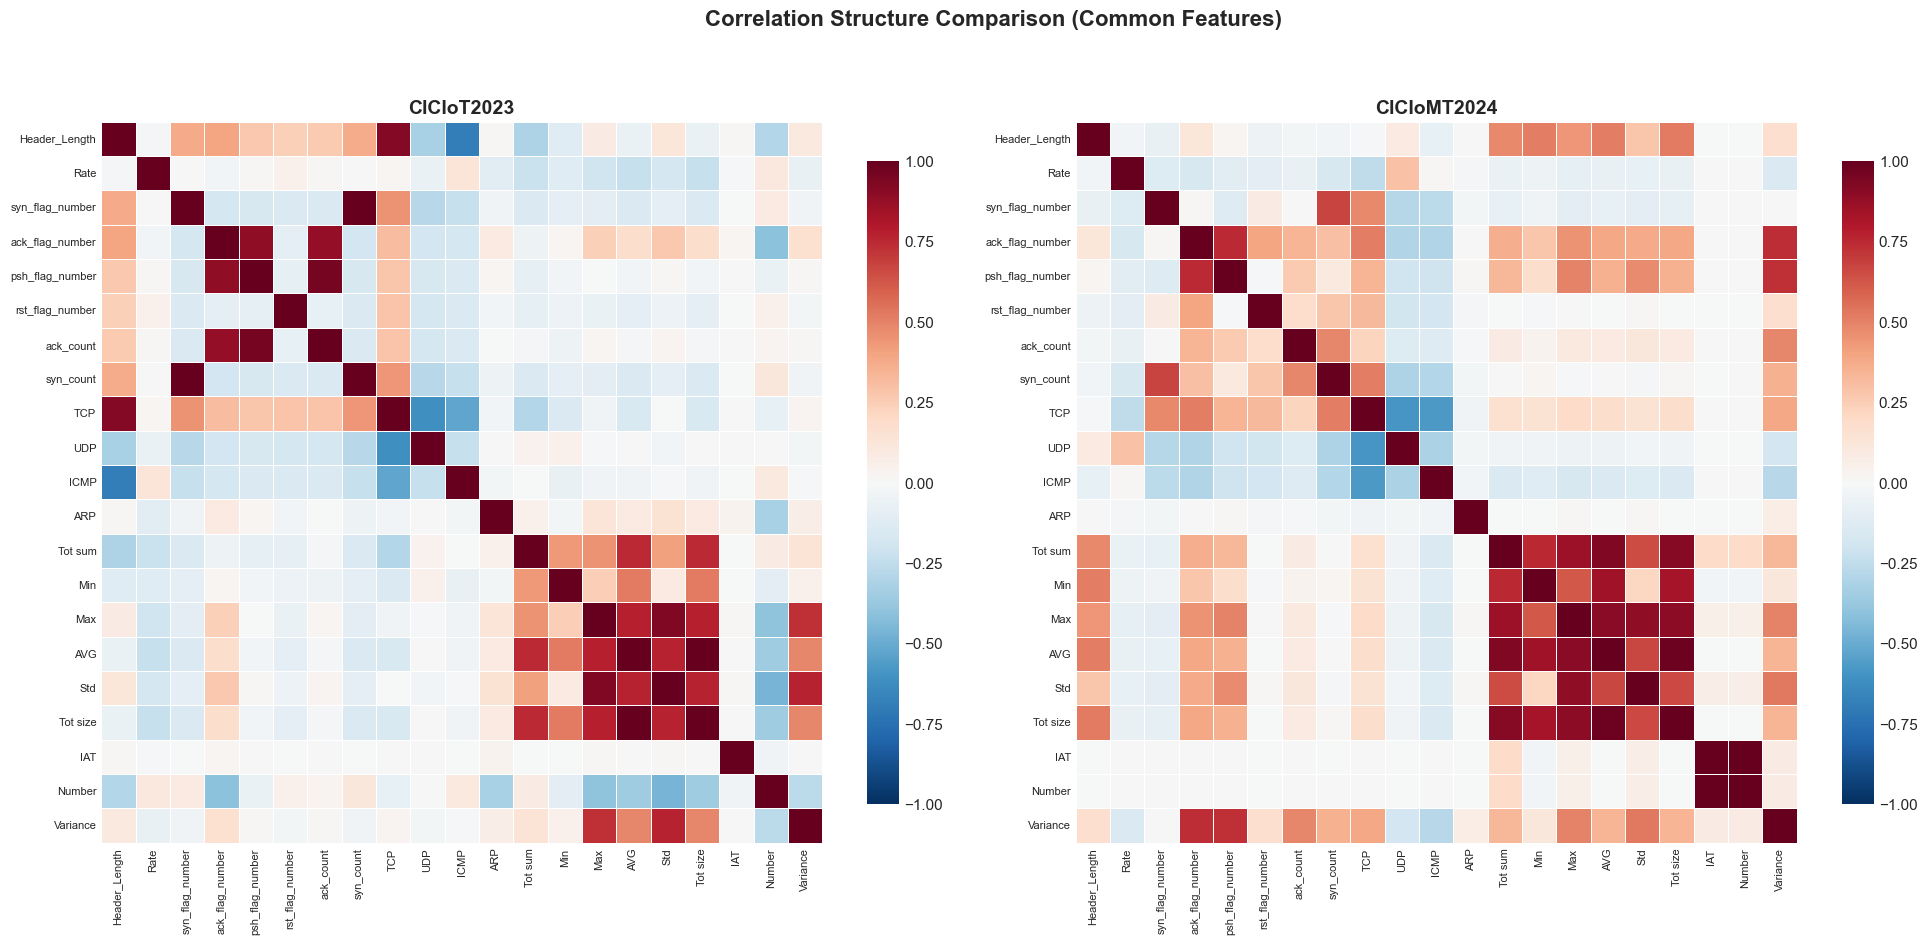

In [27]:
# ══════════════════════════════════════════════════════════════════════
# 10a. Correlation heatmaps side-by-side
# ══════════════════════════════════════════════════════════════════════

# Select common numeric features for correlation
corr_features = [
    'Header_Length', 'Rate', 'syn_flag_number', 'ack_flag_number',
    'psh_flag_number', 'rst_flag_number', 'ack_count', 'syn_count',
    'TCP', 'UDP', 'ICMP', 'ARP',
    'Tot sum', 'Min', 'Max', 'AVG', 'Std',
    'Tot size', 'IAT', 'Number', 'Variance',
]

# Compute correlations
corr_2023 = df_sample_2023[corr_features].replace([np.inf, -np.inf], np.nan).corr()
corr_2024 = df_sample_2024[corr_features].replace([np.inf, -np.inf], np.nan).corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# CICIoT2023
sns.heatmap(corr_2023, ax=axes[0], cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            xticklabels=True, yticklabels=True)
axes[0].set_title('CICIoT2023', fontsize=14, fontweight='bold')
axes[0].tick_params(labelsize=8)

# CICIoMT2024
sns.heatmap(corr_2024, ax=axes[1], cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            xticklabels=True, yticklabels=True)
axes[1].set_title('CICIoMT2024', fontsize=14, fontweight='bold')
axes[1].tick_params(labelsize=8)

plt.suptitle('Correlation Structure Comparison (Common Features)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

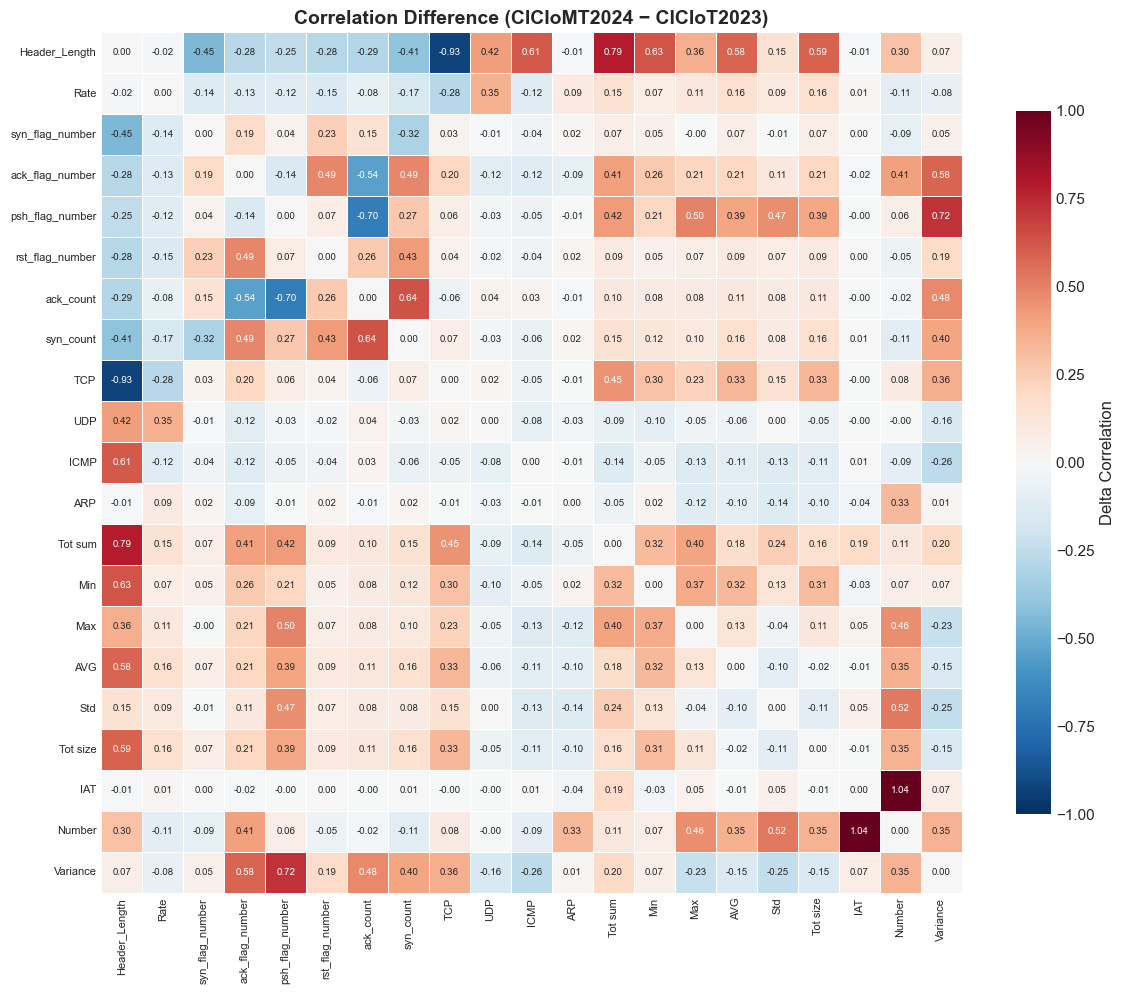


Top 10 Largest Correlation Differences
  IAT                  ↔ Number              :  Delta = +1.039
  Header_Length        ↔ TCP                 :  Delta = -0.929
  Header_Length        ↔ Tot sum             :  Delta = +0.788
  psh_flag_number      ↔ Variance            :  Delta = +0.720
  psh_flag_number      ↔ ack_count           :  Delta = -0.695
  ack_count            ↔ syn_count           :  Delta = +0.640
  Header_Length        ↔ Min                 :  Delta = +0.631
  Header_Length        ↔ ICMP                :  Delta = +0.614
  Header_Length        ↔ Tot size            :  Delta = +0.587
  Header_Length        ↔ AVG                 :  Delta = +0.581


In [28]:
# ══════════════════════════════════════════════════════════════════════
# 10b. Correlation difference heatmap
# ══════════════════════════════════════════════════════════════════════

corr_diff = corr_2024 - corr_2023

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(corr_diff, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'Delta Correlation'},
            annot=True, fmt='.2f', annot_kws={'fontsize': 7},
            xticklabels=True, yticklabels=True)
ax.set_title('Correlation Difference (CICIoMT2024 − CICIoT2023)', fontsize=14, fontweight='bold')
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

# Report biggest differences
print('\nTop 10 Largest Correlation Differences')
print('=' * 60)
# Get upper triangle
mask = np.triu(np.ones_like(corr_diff, dtype=bool), k=1)
diff_flat = corr_diff.where(mask).stack().reset_index()
diff_flat.columns = ['Feature 1', 'Feature 2', 'Delta Correlation']
diff_flat['|Delta|'] = diff_flat['Delta Correlation'].abs()
top_diffs = diff_flat.nlargest(10, '|Delta|')

for _, row in top_diffs.iterrows():
    print(f"  {row['Feature 1']:20s} ↔ {row['Feature 2']:20s}:  Delta = {row['Delta Correlation']:>+.3f}")

## 11. Summary & Integration Considerations

### Summary Findings & Integration Considerations

In [29]:
# ══════════════════════════════════════════════════════════════════════
# 11. Final Summary Report
# ══════════════════════════════════════════════════════════════════════

print('╔' + '═' * 76 + '╗')
print('║' + ' Comparative Analysis Summary Report'.center(76) + '║')
print('║' + ' CICIoT2023 vs CICIoMT2024'.center(76) + '║')
print('╠' + '═' * 76 + '╣')

print('║' + '  DATASET SCALE'.ljust(76) + '║')
print(f'║  CICIoT2023:  {iot2023_total_rows:>12,} rows | {len(iot2023_all_cols)-1} features | 34 labels'.ljust(76) + '║')
print(f'║  CICIoMT2024: {iomt2024_total_rows:>12,} rows | {len(iomt2024_all_cols)} features | 19 labels'.ljust(76) + '║')
print(f'║  Size ratio:  {iot2023_total_rows/iomt2024_total_rows:.1f}x (CICIoT2023 is larger)'.ljust(76) + '║')

print('╠' + '═' * 76 + '╣')
print('║' + '  FEATURE ALIGNMENT'.ljust(76) + '║')
print(f'║  Identical features (same name):     {n_identical}'.ljust(76) + '║')
print(f'║  Renamed features (semantic match):  {n_renamed} (Time_To_Live ↔ Duration)'.ljust(76) + '║')
print(f'║  CICIoMT2024-only features:          {n_only_2024} (Srate, Drate, Magnitue, ...)'.ljust(76) + '║')
print(f'║  → Unified feature set:              {n_identical + n_renamed} common features'.ljust(76) + '║')

print('╠' + '═' * 76 + '╣')
print('║' + '  LABEL OVERLAP'.ljust(76) + '║')
print(f'║  Shared attack types (fine-grained):    {len(shared_unified)} types'.ljust(76) + '║')
print(f'║  Only CICIoT2023:                       {len(only_from_2023)} types'.ljust(76) + '║')
print(f'║  Only CICIoMT2024:                      {len(only_from_2024)} types'.ljust(76) + '║')
print(f'║  Unified taxonomy:                      {len(all_unified)} unique labels'.ljust(76) + '║')
print(f'║  Category-level classes:                {len(all_categories_unified)} categories'.ljust(76) + '║')

print('╠' + '═' * 76 + '╣')
print('║' + '  CLASS IMBALANCE'.ljust(76) + '║')
print(f'║  CICIoT2023 Benign ratio:  {iot2023_benign/iot2023_total_rows*100:.1f}% (1:{iot2023_attack//iot2023_benign} attack:benign)'.ljust(76) + '║')
print(f'║  CICIoMT2024 Benign ratio: {iomt2024_benign/iomt2024_total_rows*100:.1f}% (1:{iomt2024_attack//iomt2024_benign} attack:benign)'.ljust(76) + '║')
print(f'║  Both datasets heavily attack-dominated'.ljust(76) + '║')

print('╠' + '═' * 76 + '╣')
print('║' + '  KEY INTEGRATION CONSIDERATIONS'.ljust(76) + '║')
print('║' + '  1. Feature alignment is excellent (39/45 features mappable)'.ljust(76) + '║')
print('║' + '  2. TTL column rename: Time_To_Live ↔ Duration'.ljust(76) + '║')
print('║' + '  3. 6 extra CICIoMT2024 features → NaN for CICIoT2023 rows'.ljust(76) + '║')
print('║' + '  4. Label harmonization needed (3-level taxonomy proposed)'.ljust(76) + '║')
print('║' + '  5. Significant size imbalance between datasets'.ljust(76) + '║')
print('║' + '  6. Both share same extraction pipeline (DPKT) → comparable'.ljust(76) + '║')
print('║' + '  7. Feature distributions differ → normalization required'.ljust(76) + '║')
print('║' + '  8. Correlation structures partially conserved'.ljust(76) + '║')
print('╚' + '═' * 76 + '╝')

╔════════════════════════════════════════════════════════════════════════════╗
║                     Comparative Analysis Summary Report                    ║
║                          CICIoT2023 vs CICIoMT2024                         ║
╠════════════════════════════════════════════════════════════════════════════╣
║  DATASET SCALE                                                             ║
║  CICIoT2023:    44,763,144 rows | 39 features | 34 labels                 ║
║  CICIoMT2024:    8,322,896 rows | 45 features | 19 labels                 ║
║  Size ratio:  5.4x (CICIoT2023 is larger)                                 ║
╠════════════════════════════════════════════════════════════════════════════╣
║  FEATURE ALIGNMENT                                                         ║
║  Identical features (same name):     38                                   ║
║  Renamed features (semantic match):  1 (Time_To_Live ↔ Duration)          ║
║  CICIoMT2024-only features:          6 (Srate, Drate, M

### Key Conclusions

#### 1. Feature Compatibility (High)
The two datasets share **39 common features** (38 with the same name + 1 renamed: `Time_To_Live` ↔ `Duration`). This means that unification at the feature level is **immediately feasible** without significant information loss. The 6 extra features of CICIoMT2024 (`Srate`, `Drate`, `Magnitue`, `Radius`, `Covariance`, `Weight`) can be filled as NaN or excluded.

#### 2. Label Overlap (Moderate)
Out of the **34 + 19 = 53** original labels, **~12 attack types** correspond semantically (DDoS/DoS floods, Recon scans, ARP Spoofing). CICIoT2023 introduces unique types (Mirai, Web-based, Brute Force), while CICIoMT2024 introduces **MQTT attacks**. The **3-level unified taxonomy** (Binary → Category → Fine-grained) fully covers both.

#### 3. Distribution Differences (Significant)
Despite using the **same extraction pipeline** (DPKT), the features exhibit **different distributions** due to:
- Different network topology
- Different devices (generic IoT vs medical IoT)
- Different attack mix

→ **Normalization** will be required during integration.

#### 4. Scale Imbalance
CICIoT2023 is **~5x larger** (44.7M vs 8.3M rows). This requires a **sampling or weighting** strategy to prevent CICIoT2023 from dominating the unified dataset.

#### 5. Shared Pipeline Advantage
The use of the **same feature extraction tool** (DPKT) and the **same window-based aggregation** strategy by the same laboratory (CIC, UNB) means that the features are **inherently compatible** — no re-extraction from PCAPs is needed.